# The goal of this project is to predict used-vehicle asking prices using the used_car_dataset. By analysing historical vehicle data and training a machine learning model, I aim to estimate the prices of future vehicles that enter the market.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv(r'C:\Users\Leboh\Py\used_car_dataset.csv')

LOADING THE DATASET

In [2]:

df = pd.DataFrame(data)

THIS IS WHERE I CHECK THE STRUCTURE AND QUALITY OF THE DATA TO SEE IF THERE IS ANYTHING THAT I NEED TO FIX

In [3]:
print(df.shape)

(24575, 11)


FROM THIS OBSERVATION I CAN SEE THAT WE HAVE A SHAPE OF 11 COLUMNS AND 24575 RECORDS

In [4]:
print(df.head())


           Brand  model    Year   Age     kmDriven Transmission   Owner  \
0            NaN    NaN  2001.0  23.0    98,000 km          NaN     NaN   
1         Toyota    NaN     NaN  15.0  190000.0 km       Manual     NaN   
2     Volkswagen    NaN  2010.0   NaN          NaN       Manual   first   
3            NaN  Swift  2017.0   7.0          NaN       Manual  second   
4  Maruti Suzuki    NaN  2019.0   5.0          NaN    Automatic     NaN   

  FuelType PostedDate                                       AdditionInfo  \
0  Unknown     Nov-24  Honda City v teck in mint condition, valid gen...   
1   Diesel     Jul-24  Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...   
2      NaN     Nov-24  Volkswagen Vento 2010-2013 Diesel Breeze, 2010...   
3  Unknown        NaN     Maruti Suzuki Swift 2017 Diesel Good Condition   
4  Unknown     Nov-24       Maruti Suzuki Baleno Alpha CVT, 2019, Petrol   

     AskPrice  
0  ₹ 1,95,000  
1  ₹ 3,75,000  
2  ₹ 1,84,999  
3  ₹ 5,65,000  
4  ₹ 6,85,00

FROM THIS I CAN SEE THAT THERE SEEMS TO BE 4 NUMERIC COLUMNS AND 7 NON-NUMERIC COLUMNS

In [5]:
print(df.columns)


Index(['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice'],
      dtype='str')


I CAN MAKE EARLY ASSUMPTIONS THAT THE LEAST IMPORTANT COLUMNS FROM THIS DATASET ARE PROBABLY 'ADDITIONAL INFO' AND 'POSTED DATA', HOWEVER THOSE ARE PRE-ASSUMPTIONS THAT WILL STILL BE INVESTIGATED

In [6]:
print(f"{df.describe()} '\n' {df.info()}")


<class 'pandas.DataFrame'>
RangeIndex: 24575 entries, 0 to 24574
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         19306 non-null  str    
 1   model         14144 non-null  str    
 2   Year          19396 non-null  float64
 3   Age           18600 non-null  float64
 4   kmDriven      18344 non-null  str    
 5   Transmission  18653 non-null  str    
 6   Owner         13949 non-null  str    
 7   FuelType      19336 non-null  str    
 8   PostedDate    18355 non-null  str    
 9   AdditionInfo  24575 non-null  str    
 10  AskPrice      24575 non-null  str    
dtypes: float64(2), str(9)
memory usage: 2.1 MB
               Year           Age
count  19396.000000  18600.000000
mean    4118.984327      7.676398
std     3516.311608      4.293379
min     1900.000000      0.000000
25%     2015.000000      5.000000
50%     2018.000000      7.000000
75%     9999.000000     10.000000
max     9999.000000    

FROM THE DESCRIPTION OF THE DATA I CAN SEE THAT THERE A FEW MISSING/NULL FROM MOST OF THE COLUMNS, THE IMFORMATION ABOUT THE DATA ON THE OTHER HAND THE OTHER HAND SHOWS ME THAT THE STATS IS NORMAL, THE DISTRIBUTION DOES NOT LOOK OFF ON MOST OF THE NUMERIC COLUMNS.

THE MIGHT BE A FEW OUTLIERS THOUGH ON THE 'ASKPRICE; COLUMN THAT NEED TO BE DEALT WITH

In [7]:
df.isna().sum()

Brand            5269
model           10431
Year             5179
Age              5975
kmDriven         6231
Transmission     5922
Owner           10626
FuelType         5239
PostedDate       6220
AdditionInfo        0
AskPrice            0
dtype: int64

FROM THIS WE CAN SEE THAT ALL OF THE COLUMNS HAVE MISSING VALUES EXCEPT FOR 'ADDITIONAL INFO' AND 'ASK PRICE'

In [8]:
missing_percentage = (df.isnull().mean() * 100).round(2)

print(missing_percentage.sort_values(ascending=False))

Owner           43.24
model           42.45
kmDriven        25.36
PostedDate      25.31
Age             24.31
Transmission    24.10
Brand           21.44
FuelType        21.32
Year            21.07
AdditionInfo     0.00
AskPrice         0.00
dtype: float64


THIS SHOWS THE PERCENTAGE OF MISSING VALUES, THE 'OWNER' COLUMN HAS THE MOST FOLLOWED BY 'MODEL'

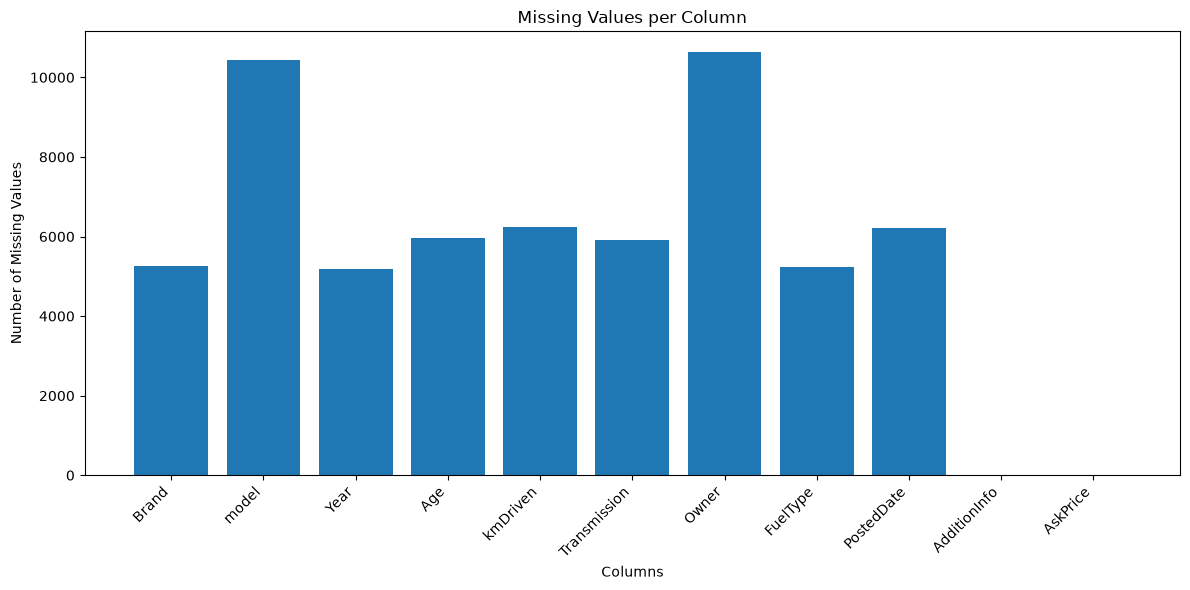

In [9]:
missing_values = df.isnull().sum()

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(missing_values.index, missing_values.values)

ax.set_title('Missing Values per Column')
ax.set_xlabel('Columns')
ax.set_ylabel('Number of Missing Values')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

THIS SHOWS THE VISULISATION OF MISSING VALUES PER COLUMN

In [10]:
print("Total rows:", df.shape[0])
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

Total rows: 24575
Exact duplicate rows: 9587
Unique rows: 14988


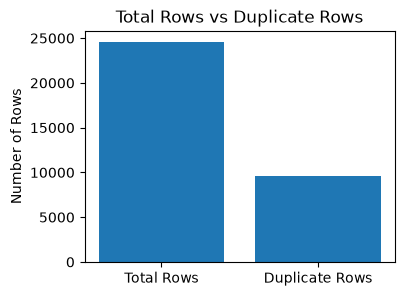

In [11]:
x = df.shape[0]
y = df.duplicated().sum()

fig, ax = plt.subplots(figsize=(4, 3))

ax.bar(['Total Rows', 'Duplicate Rows'], [x, y], width=0.8)

ax.set_title('Total Rows vs Duplicate Rows')
ax.set_ylabel('Number of Rows')

plt.show()

THIS IS THE VISUALISATION OF THE MISSING VALUES COMPARED TO THE TOTAL VALUES

In [12]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values(
    by=['Brand', 'model', 'Year']
).head(20)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
8772,Ambassador,NaN,9999.0,21.0,1 km,NaN,second,NaN,Nov-24,Ambassador isuzu,"₹ 1,55,000"
18354,Ambassador,NaN,9999.0,21.0,1 km,NaN,second,NaN,Nov-24,Ambassador isuzu,"₹ 1,55,000"
2455,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,NaN,NaN,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
3383,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,Diesel,Nov-24,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
12037,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,NaN,NaN,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
12965,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,Diesel,Nov-24,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
23,Audi,A3,9999.0,9.0,"42,000 km",Automatic,NaN,NaN,Nov-24,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
1535,Audi,A3,9999.0,10.0,"44,000 km",NaN,NaN,Unknown,Nov-24,"Audi A3 2.0 35 TDI Premium + Sunroof, 2014, Di...","₹ 16,70,000"
2102,Audi,A3,9999.0,NaN,"94,000 km",Automatic,NaN,Diesel,Nov-24,"Audi A3 2.0 35 TDI Premium + Sunroof, 2016, Di...","₹ 13,99,000"
3171,Audi,A3,9999.0,8.0,NaN,NaN,second,NaN,NaN,"Audi A3 35 TDI S Line, 2016, Diesel","₹ 9,49,000"


THIS CODE SHOWS ME THE EXACT DUPLICATES BOTH THE ORIGINAL VALUE AND SUBSEQUENT DUPLICATES. ON SOME FEATURES THE DUPLICATED HAVE MISSING VALUES 

In [13]:
df[df.duplicated(subset=['kmDriven'], keep=False)].sort_values(by='kmDriven')

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
24436,Toyota,Innova Hycross,2024.0,0.0,0 km,Automatic,NaN,hybrid,Nov-24,"Toyota Innova Hycross 2.0 ZX (O) Hybrid 7 STR,...","₹ 31,34,000"
20548,Maruti Suzuki,Alto-800,2024.0,0.0,0 km,Automatic,first,hybrid,Dec-24,Garage shedl for sale,"₹ 2,80,000"
21119,Honda,City,2011.0,13.0,0 km,Automatic,second,hybrid,Dec-24,Honda City 2011 CNG &r Hybrids Well Maintained,"₹ 2,00,000"
9093,Unknown,CERATO,2024.0,0.0,0 km,NaN,NaN,Unknown,Nov-24,Kia CERATO 2024,"₹ 45,000"
24375,Toyota,Innova Hycross,2024.0,0.0,0 km,Automatic,first,hybrid,Nov-24,"Toyota Innova Hycross 2.0 ZX (O) Hybrid 7 STR,...","₹ 31,34,000"
...,...,...,...,...,...,...,...,...,...,...,...
24199,Land Rover,Discovery Sport,2020.0,4.0,NaN,Automatic,first,Diesel,Nov-24,Land Rover Discovery Sport S 2020 Diesel Autom...,"₹ 35,00,000"
24283,Tata,Tigor,2024.0,0.0,NaN,Automatic,first,hybrid,Nov-24,Tata Tigor 2024,"₹ 9,25,000"
24297,Maruti Suzuki,Baleno,2019.0,5.0,NaN,Manual,first,hybrid,Nov-24,"Maruti Suzuki Baleno Delta, 2019, CNG & Hybrids","₹ 5,95,000"
24333,Hyundai,i10,2011.0,13.0,NaN,Automatic,first,NaN,Nov-24,"Hyundai i10 Sportz 1.2 Automatic Kappa2, 2011,...","₹ 2,75,000"


USING THE 'KMDRIVEN' COLUMN WE CAN SEE THAT SOME CARS HABE SIMILAR MILEAGES AND THEY ARE NOT NECESSARILY DUPLICATES

In [14]:
df[df.duplicated(subset=['Brand', 'model', 'Year', 'kmDriven'], keep=False)].sort_values(by=['Brand', 'model', 'Year'])

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
8772,Ambassador,NaN,9999.0,21.0,1 km,NaN,second,NaN,Nov-24,Ambassador isuzu,"₹ 1,55,000"
18354,Ambassador,NaN,9999.0,21.0,1 km,NaN,second,NaN,Nov-24,Ambassador isuzu,"₹ 1,55,000"
2455,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,NaN,NaN,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
3383,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,Diesel,Nov-24,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
12037,Audi,A3,2015.0,NaN,"42,000 km",NaN,NaN,NaN,NaN,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel","₹ 10,50,000"
...,...,...,...,...,...,...,...,...,...,...,...
18921,NaN,NaN,NaN,NaN,"60,000 km",Automatic,second,Hybrid/CNG,NaN,Maruti Suzuki Zen Estilo 2010,"₹ 90,000"
18923,NaN,NaN,NaN,10.0,"41,100 km",NaN,NaN,Petrol,Oct-24,"Maruti Suzuki Omni 8 Seater, 2014, Petrol","₹ 2,90,000"
18996,NaN,NaN,NaN,NaN,"98,000 km",Manual,first,Petrol,Nov-24,"Tata Zest, 2016, Petrol","₹ 4,25,000"
19030,NaN,NaN,NaN,8.0,NaN,Automatic,first,Petrol,Nov-24,"Hyundai Grand i10 2016-2017 Asta Option AT, 20...","₹ 4,90,000"


INVESTIGATING FURTHER I CAN SEE THAT THEY LOOK TO BE DUPLICATES HOWEVER DUE TO THE NULLS, I CANNOT GO AHEAD AND MAKE THE DECISION TO DELETE THEM

BELOW IS THE SECTION WHERE I START MY DATA CLEANING PROCESS

In [15]:
brand_list = df['Brand'].unique().tolist()
brand_list

[nan,
 'Toyota',
 'Volkswagen',
 'Maruti Suzuki',
 'BMW',
 'Unknown',
 'Ford',
 'Mercedes-Benz',
 'Hyundai',
 'Kia',
 'Honda',
 'Audi',
 'Renault',
 'Skoda',
 'MG',
 'Mini',
 'Mahindra',
 'Tata',
 'Jeep',
 'Land Rover',
 'Volvo',
 'Porsche',
 'Nissan',
 'Jaguar',
 'Force',
 'Fiat',
 'Chevrolet',
 'Lexus',
 'Datsun',
 'Mitsubishi',
 'Rolls-Royce',
 'Bajaj',
 'Opel',
 'Isuzu',
 'Bentley',
 'Ssangyong',
 'Ambassador',
 'Maserati',
 'Toyota Land',
 'Citroen',
 'Lamborghini',
 'Hummer']

In [16]:
df['AdditionInfo'].sample(20)

13032                 Maruti Suzuki Alto K10, 2016, Petrol
21607                    Honda City i-VTEC V, 2017, Petrol
9084                       Ford Fiesta Classic 2015 diesel
17925    Maruti Suzuki Wagon R 2011 Petrol 33600 Km Dri...
16872         Mini Countryman Shadow Edition, 2012, Petrol
16004    Maruti Suzuki Swift Dzire 2019 Diesel 90000 Km...
22816    Hyundai Grand i10 1.2 Sportz SPECIAL Edition V...
11607    Maruti Suzuki Alto K10 2017 Petrol 84000 Km Dr...
22214     Ford Endeavour 2.2 Titanium AT 4X2, 2018, Diesel
9501                                           Sunroof car
10904    Toyota Innova 2.5 G (Diesel) 8 Seater, 2014, D...
17969              Audi A4 2.0 35 TDI S Line, 2017, Diesel
18228    Ford Ecosport 1.5 Diesel Titanium Plus, 2017, ...
13536        Maruti Suzuki Ciaz Delta Diesel, 2017, Diesel
20983       Volkswagen Polo 1.5 TDI Highline, 2015, Diesel
20294    Hyundai Grand i10 1.2 Kappa Magna, 2019, CNG &...
6372                Honda Amaze V CVT Petrol, 2018, Petr

In [17]:
# new_list = []
# for val in brand_list:
#     if isinstance(val, str):
#         if df['AdditionInfo'].str.contains(val, na=False, regex=False).any():
#                 new_list.append(val)
        
for val in brand_list:
    if isinstance(val, str):
        df.loc[df['AdditionInfo'].str.contains(val, na=False, regex=False) & df['Brand'].isna() | (df['Brand'] == 'Unknown'), 'Brand'] = val

df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,NaN,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


I REMOVED NULL VALUES IN THE BRAND COLUMN USING THE ADDITIONAL INFO COLUMN, I AM THINKING OF APPLYING THE SAME CODE TO THE REST OF THE COLUMNS WHICH CONTAIN NULL VALUES SHOULD THEY BE ON THE ADDITIONAL INFO COLUMN

In [18]:
df['Brand'].unique()

<StringArray>
[        'Honda',        'Toyota',    'Volkswagen', 'Maruti Suzuki',
           'BMW',          'Ford',           'Kia', 'Mercedes-Benz',
       'Hyundai',          'Audi',       'Renault',            'MG',
         'Skoda',          'Tata',      'Mahindra',          'Mini',
             nan,          'Jeep',        'Jaguar',    'Land Rover',
         'Volvo',       'Porsche',        'Nissan',         'Force',
          'Fiat',         'Isuzu',     'Chevrolet',         'Lexus',
    'Mitsubishi',        'Datsun',   'Rolls-Royce',         'Bajaj',
          'Opel',       'Bentley',     'Ssangyong',    'Ambassador',
      'Maserati',   'Toyota Land',       'Citroen',   'Lamborghini',
        'Hummer']
Length: 41, dtype: str

In [19]:
model_list = df['model'].unique().tolist()
model_list

[nan,
 'Swift',
 'Ecosport',
 'Alto-K10',
 'Swift-Dzire',
 '3 Series GT',
 'Endeavour',
 'A3',
 'Hector',
 'S90',
 'Ertiga',
 'Innova Crysta',
 'C-Class',
 'City',
 'Creta',
 'Fortuner',
 'XUV500',
 'i10',
 'Carens',
 'Xcent',
 'Ritz',
 'Cooper 3 DOOR',
 'Polo',
 'Nexon',
 'CrossPolo',
 'Baleno',
 'Celerio',
 'Range Rover Evoque',
 'Indigo Ecs',
 'Thar',
 'Kushaq',
 'Grand i10',
 'Bolero',
 'Brio',
 'VentoTest',
 'A4',
 'Eon',
 'Altroz',
 'Grand i10 Nios',
 'X1',
 'i20',
 'Swift Dzire',
 'Alto K10',
 'Seltos',
 'Glanza',
 'Rapid',
 'Alto-800',
 'Omni',
 'Cruze',
 'Verna',
 'Dzire',
 'Q7',
 'GLE COUPE',
 'Cooper 5 DOOR',
 'Alto',
 'Creta Facelift',
 'Bolt',
 'XF',
 'Tiago',
 'Indigo Marina',
 'Safari',
 'Nano Genx',
 'Tiguan',
 'G',
 'XC 90',
 'Amaze',
 'Virtus',
 'A-Star',
 'Cooper S',
 'Etios Liva',
 'CLA',
 'XUV700',
 'Alturas G4',
 'ASTOR',
 'A6',
 'GLA Class',
 'Linea',
 'Ciaz',
 'maruti-suzuki-brezza',
 'Alcazar',
 'Elite i20',
 'Captur',
 'E-Class',
 'KUV 100',
 'Range Rover',
 '

In [20]:
for val in model_list:
    if isinstance(val, str):
        df.loc[df['AdditionInfo'].str.contains(val, na=False, regex=False) & df['model'].isna() | (df['model'] == 'Unknown'), 'model'] = val

df.sample(20)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
16180,Hyundai,Elantra,2017.0,7.0,NaN,NaN,second,Hybrid/CNG,Nov-24,"Hyundai Elantra 2.0 SX Option AT, 2017, CNG & ...","₹ 8,99,000"
22573,Hyundai,Verna,2018.0,6.0,"83,000 km",Automatic,first,Diesel,Nov-24,"Hyundai Verna CRDi 1.6 SX, 2018, Diesel","₹ 7,95,000"
21529,Hyundai,Santro Xing,2003.0,21.0,"49,000 km",Automatic,second,hybrid,Dec-24,Santro xing automatic transmission 2003 CNG,"₹ 1,35,000"
883,Honda,City,2017.0,7.0,"28,305 km",Automatic,NaN,Petrol,Nov-24,"Honda City i-VTEC CVT V, 2017, Petrol","₹ 6,81,000"
21396,Audi,A4,2023.0,1.0,"4,000 km",Automatic,first,Petrol,Nov-24,"Audi A4 2.0 Technology 40 TFSI, 2023, Petrol","₹ 43,00,000"
6978,Toyota,Wagon-R-1-0,2014.0,NaN,NaN,Automatic,second,Hybrid/CNG,NaN,Maruti Suzuki Wagon R 1.0 2014 CNG & Hybrids 7...,"₹ 1,95,000"
19923,Hyundai,Verna,2013.0,11.0,"90,000 km",Manual,second,Diesel,Nov-24,"Hyundai Verna 2011-2014 1.6 SX CRDi (O), 2013,...","₹ 3,45,000"
4502,Maruti Suzuki,Ertiga,2013.0,11.0,NaN,NaN,first,NaN,Nov-24,Maruti Suzuki Ertiga 2013 Diesel 85000 Km Driven,"₹ 4,70,000"
13375,Toyota,Wagon-R,2004.0,20.0,"95,000 km",NaN,NaN,Petrol,Nov-24,Maruti Suzuki Wagon R 2004,"₹ 1,20,000"
19723,Audi,A4,2014.0,10.0,"72,000 km",Automatic,second,Diesel,Nov-24,"Audi A4 2.0 TDI, 2014, Diesel","₹ 7,25,000"


In [21]:
import re

for i in df.index:
    if pd.isna(df.loc[i, 'Year']) or df.loc[i, 'Year'] == 9999.0:
        info = str(df.loc[i, 'AdditionInfo'])
        match = re.search(r'\b(?:19\d{2}|20[0-2]\d)\b', info)

        if match:
            year = int(match.group())

            if 1990 <= year <= 2026:
                df.loc[i, 'Year'] = year

df.head(20)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,G,2009.0,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,Vento,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
5,BMW,X3,2014.0,NaN,"83,000 km",NaN,first,Unknown,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel","₹ 13,50,000"
6,Toyota,Innova,2014.0,10.0,"168,000 km",Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel","₹ 10,25,000"
7,BMW,5 Series,2019.0,5.0,NaN,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel","₹ 59,50,000"
8,Maruti Suzuki,Dzire,2020.0,NaN,"33,759 km",Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol","₹ 6,22,000"
9,Ford,Ecosport,2017.0,NaN,NaN,Manual,second,NaN,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...","₹ 6,49,000"


I ADDED THE YEARS ON THE ROWS THAT THEY WERE MISSING AND WERE THEY WERE 9999.0

In [22]:
current_year = df.loc[0, 'Year'] + df.loc[0, 'Age']

for val in df.index:
    if pd.isna(df.loc[val, 'Age']) & pd.notna(df.loc[val, 'Year']):
        df.loc[val, 'Age'] = current_year - df.loc[val, 'Year']

df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,G,2009.0,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,Vento,2010.0,14.0,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
5,BMW,X3,2014.0,10.0,"83,000 km",NaN,first,Unknown,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel","₹ 13,50,000"
6,Toyota,Innova,2014.0,10.0,"168,000 km",Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel","₹ 10,25,000"
7,BMW,5 Series,2019.0,5.0,NaN,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel","₹ 59,50,000"
8,Maruti Suzuki,Dzire,2020.0,4.0,"33,759 km",Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol","₹ 6,22,000"
9,Ford,Ecosport,2017.0,7.0,NaN,Manual,second,NaN,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...","₹ 6,49,000"


I ADDED VALUES ON THE AGE COLUMN WHERE THEY WERE MISSING BY CALCULATING THE CURRENT YEAR AND USING IT TO FILL MISSING ONES

In [23]:
before_impute = df['kmDriven'].isna().sum()
before_impute

np.int64(6231)

In [24]:
for i in df.index:
    if pd.isna(df.loc[i, 'kmDriven']):
        info = str(df.loc[i, 'AdditionInfo'])

        match = re.search(r'(\d[\d\s,]*)\s*km\b', info, re.IGNORECASE)

        if match:
            df.loc[i, 'kmDriven'] = re.sub(r'[\s,]', '', match.group(1))

df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,G,2009.0,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,Vento,2010.0,14.0,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
5,BMW,X3,2014.0,10.0,"83,000 km",NaN,first,Unknown,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel","₹ 13,50,000"
6,Toyota,Innova,2014.0,10.0,"168,000 km",Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel","₹ 10,25,000"
7,BMW,5 Series,2019.0,5.0,NaN,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel","₹ 59,50,000"
8,Maruti Suzuki,Dzire,2020.0,4.0,"33,759 km",Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol","₹ 6,22,000"
9,Ford,Ecosport,2017.0,7.0,NaN,Manual,second,NaN,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...","₹ 6,49,000"


I APPLIED A SIMILAR APPROACH THAT I USED BEFORE TO IMPUTE MISSING VALUES ON THE KMDRIVEN COLUMN EXTRACTED FROM THE ADDITIONAL INFO COLUMN, AFTER EXTRACTING I CAN SEE THERE ARE STILL A LOT OF VALUES MISSING

In [25]:
after_impute = df['kmDriven'].isna().sum()
after_impute

np.int64(5653)

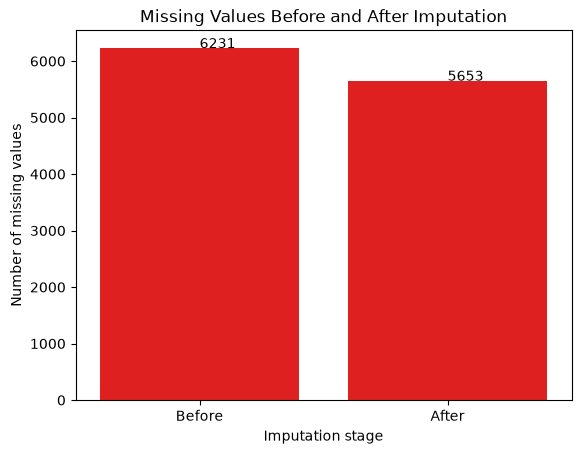

In [26]:
import seaborn as sns

sns.barplot(x=['Before', 'After'], y=[before_impute, after_impute], color='red')

plt.xlabel('Imputation stage')
plt.ylabel('Number of missing values')
plt.title('Missing Values Before and After Imputation')

plt.annotate(before_impute, (0, before_impute))
plt.annotate(after_impute, (1, after_impute))
plt.show()

THIS VISUALISATION SHOWS THE DIFFERENCE BEFORE AND AFTER IMPUTING THE MISSING VALUES ON THE KMDRIVEN COLUMN

In [27]:
df['AskPrice'] = df['AskPrice'].str.replace('₹', '')
df['AskPrice'] = df['AskPrice'].str.replace(',', '')
df['AskPrice'] = df['AskPrice'].astype(float)

df['kmDriven'] = df['kmDriven'].str.replace(',', '')
df['kmDriven'] = df['kmDriven'].str.replace('km', '')
df['kmDriven'] = df['kmDriven'].astype(float)

df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,98000.0,NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,G,2009.0,15.0,190000.0,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,Vento,2010.0,14.0,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0
...,...,...,...,...,...,...,...,...,...,...,...
24570,Maruti Suzuki,Wagon-R,2022.0,2.0,31000.0,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0
24571,BMW,X1,2017.0,7.0,45000.0,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0
24572,Maruti Suzuki,New-gen Swift,2011.0,13.0,60000.0,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0
24573,Tata,Zest,2019.0,5.0,62000.0,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0


I CLEANED THE DATA BY REMOVING THE STRING VALUES FROM THE KMDRIVEN COLUMNS AND ASKPRICE COLUMN AND CONVERTED THEM INTO FLOATS

In [28]:
df['kmDriven'] = df['kmDriven'].fillna(
    np.mean(df['kmDriven'])
)

df['kmDriven'].isna().sum()


np.int64(0)

In [29]:
df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,98000.000000,NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0
5,BMW,X3,2014.0,10.0,83000.000000,NaN,first,Unknown,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0
6,Toyota,Innova,2014.0,10.0,168000.000000,Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel",1025000.0
7,BMW,5 Series,2019.0,5.0,80089.393405,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0
8,Maruti Suzuki,Dzire,2020.0,4.0,33759.000000,Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol",622000.0
9,Ford,Ecosport,2017.0,7.0,80089.393405,Manual,second,NaN,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...",649000.0


In [30]:
df['Transmission'].isna().sum()

np.int64(5922)

In [31]:

for val in ['Automatic', 'Manual']:
    df.loc[
        df['AdditionInfo'].astype(str).str.contains(
            val, case=False, na=False, regex=False
        ) & df['Transmission'].isna(),
        'Transmission'
    ] = val

df['Transmission'].isna().sum()

np.int64(5715)

FROM THE SUM OF THE MISSING VALUES ON THE TRANSMISSION COLUMN BEFORE AND AFTER i CAN SEE THAT THERE IS STILL A LARGE NUMBER OF MISSING VALUES

In [32]:
df['Transmission'] = df['Transmission'].fillna(df['Transmission'].mode()[0])

df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0
5,BMW,X3,2014.0,10.0,83000.000000,Automatic,first,Unknown,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0
6,Toyota,Innova,2014.0,10.0,168000.000000,Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel",1025000.0
7,BMW,5 Series,2019.0,5.0,80089.393405,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0
8,Maruti Suzuki,Dzire,2020.0,4.0,33759.000000,Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol",622000.0
9,Ford,Ecosport,2017.0,7.0,80089.393405,Manual,second,NaN,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...",649000.0


In [33]:
df['FuelType'].unique()

<StringArray>
['Unknown', 'Diesel', nan, 'Petrol', 'Hybrid/CNG', 'hybrid']
Length: 6, dtype: str

In [34]:
for val in ['Diesel', 'Petrol', 'Hybrid/CNG', 'hybrid']:
    df.loc[
        df['AdditionInfo'].astype(str).str.contains(
            val, case=False, na=False, regex=False
        ) & (
            df['FuelType'].isna() | (df['FuelType'] == 'Unknown')
        ),
        'FuelType'
    ] = val

df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Diesel,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0
5,BMW,X3,2014.0,10.0,83000.000000,Automatic,first,Diesel,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0
6,Toyota,Innova,2014.0,10.0,168000.000000,Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel",1025000.0
7,BMW,5 Series,2019.0,5.0,80089.393405,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0
8,Maruti Suzuki,Dzire,2020.0,4.0,33759.000000,Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol",622000.0
9,Ford,Ecosport,2017.0,7.0,80089.393405,Manual,second,Petrol,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...",649000.0


In [35]:
df['FuelType'] =  df['FuelType'].fillna(df['FuelType'].mode()[0])

df['FuelType'].isna().sum()

np.int64(0)

I APPLIED THE SAME IDEA ON THE FUELTYPE COLUMN WHERE I TRY TO EXTRACT THE DATA INITIALLY THEN IF I CAN'T FIND IT IMPUTE USING THE MEAN

In [36]:
df['PostedDate'].unique()

<StringArray>
['Nov-24', 'Jul-24',      nan, 'Oct-24', 'Aug-24', 'Sep-24', 'May-24',
 'Jun-24', 'Apr-24', 'Jan-24', 'Dec-23', 'Mar-24', 'Dec-24']
Length: 13, dtype: str

In [37]:
df['PostedDate'].isna().sum()


np.int64(6220)

In [38]:
df.loc[df['PostedDate'].isna(), 'AdditionInfo'].head(20).to_list()

['Maruti Suzuki Swift 2017 Diesel Good Condition',
 'Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017, Petrol',
 'Hyundai Xcent S 1.2 OPT, 2018, Diesel',
 'Maruti Suzuki Ertiga 2017 Petrol 59000 Km Driven',
 'BMW 3 Series GT 320d Luxury Line, 2015, Diesel',
 'Honda City S MT, 2010, Petrol',
 'Maruti Suzuki Vitara Brezza ZDi, 2018, Diesel',
 'Toyota Innova Crysta 2.4 V 8 STR, 2017, Diesel',
 'Toyota Innova 2.5 VX 8 STR, 2011, Diesel',
 'Creta Top model Night Edition 2023 Petrol Well Maintained',
 'Hyundai Alcazar, 2022, Diesel',
 'Hyundai i20 Magna Plus, 2019, Petrol',
 'Hyundai Creta 1.4 SX (O) Turbo Petrol DCT, 2022, Petrol',
 'Mercedes-Benz C-Class C 200, 2016, Petrol',
 'Hyundai Creta, 2017, Petrol',
 'Maruti Suzuki Wagon R 2011',
 'MG Hector Plus 1.5 Sharp DCT, 2020, Petrol',
 'Hyundai Creta 1.6 VTVT SX AT, 2017, Petrol',
 'Mercedes-Benz GLA Class 2014-2017 200 CDI SPORT, 2018, Diesel',
 'Kia Carens 1.4 Prestige 7 STR, 2023, Petrol']

In [39]:
df.loc[df['PostedDate'].notna(), ['PostedDate', 'AdditionInfo']].head(10)

,PostedDate,AdditionInfo
0,Nov-24,"Honda City v teck in mint condition, valid gen..."
1,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D..."
2,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010..."
4,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol"
5,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel"
6,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel"
7,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel"
8,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol"
10,Nov-24,"Maruti Suzuki Alto K10 VXI Airbag, 2018, Petrol"
11,Nov-24,"Kia Carnival Premium 8 STR, 2021, Diesel"


In [40]:
df.loc[
    df['PostedDate'].isna(),
    ['PostedDate', 'AdditionInfo']
].head(20)

,PostedDate,AdditionInfo
3,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition
9,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,..."
15,NaN,"Hyundai Xcent S 1.2 OPT, 2018, Diesel"
18,NaN,Maruti Suzuki Ertiga 2017 Petrol 59000 Km Driven
19,NaN,"BMW 3 Series GT 320d Luxury Line, 2015, Diesel"
22,NaN,"Honda City S MT, 2010, Petrol"
28,NaN,"Maruti Suzuki Vitara Brezza ZDi, 2018, Diesel"
30,NaN,"Toyota Innova Crysta 2.4 V 8 STR, 2017, Diesel"
31,NaN,"Toyota Innova 2.5 VX 8 STR, 2011, Diesel"
35,NaN,Creta Top model Night Edition 2023 Petrol Well...


In [41]:
df.loc[0:70, ['PostedDate', 'AdditionInfo']]

,PostedDate,AdditionInfo
0,Nov-24,"Honda City v teck in mint condition, valid gen..."
1,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D..."
2,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010..."
3,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition
4,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol"
...,...,...
66,NaN,"Kia Carens 1.4 Prestige 7 STR, 2023, Petrol"
67,Nov-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2011, D..."
68,NaN,"Maruti Suzuki Ignis 1.2 Zeta MT, 2023, Petrol"
69,NaN,"Hyundai Grand i10 2016-2017 Magna, 2017, Petrol"


HERE I WAS INVESTIGATING THE ADDITIONAL INFO, WHETHER IT HAS DATES SOI CAN EXTRACT THEM HOWEVER I FOUND VERY FEW THAT HAD THEM

In [42]:
for i in df.index:
    if pd.isna(df.loc[i, 'PostedDate']):
        info = str(df.loc[i, 'AdditionInfo'])
        match = re.search(r'[A-Za-z]{3}-\d{2}', info)

        if match:
            df.loc[i, 'PostedDate'] = match.group()

THE FIRST APPROACH ONLY FOUND 6

In [43]:
df['PostedDate'].isna().sum()

np.int64(6214)

I HAVE DECIDED TO LEAVE THE ONES THAT ARE MISSING AS THEY ARE, AS DROPPING THEM MAY LEAD TO INACCURACY

In [44]:
df.sample(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
10689,Maruti Suzuki,Baleno,2020.0,4.0,45124.000000,Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Delta, 2020, Petrol",650000.0
17177,Toyota,G,2014.0,10.0,68000.000000,Automatic,NaN,hybrid,Nov-24,"Toyota Corolla Altis VL, 2014, CNG & Hybrids",585000.0
5731,Maruti Suzuki,Baleno,2018.0,6.0,78000.000000,Automatic,NaN,hybrid,Sep-24,"Maruti Suzuki Baleno 1.3 Delta, 2018, CNG & Hy...",500000.0
22786,MG,Hector,2019.0,5.0,61000.000000,Automatic,first,Petrol,Nov-24,"MG Hector SHARP DCT PETROL, 2019, Petrol",1050000.0
1995,Maruti Suzuki,Wagon-R,2017.0,7.0,43000.000000,Automatic,NaN,Petrol,NaN,"Maruti Suzuki Wagon R VXI 1.2, 2017, Petrol",425000.0
11186,Maruti Suzuki,Ciaz,2020.0,4.0,80089.393405,Manual,NaN,Petrol,NaN,"Maruti Suzuki Ciaz Alpha 1.5 AT, 2020, Petrol",890000.0
19834,Honda,Accord,2010.0,14.0,80000.000000,Automatic,second,hybrid,Nov-24,"Honda Accord 2.4 Inspire Automatic, 2010, CNG ...",315000.0
14385,Maruti Suzuki,Brezza,2023.0,1.0,25000.000000,Manual,NaN,Hybrid/CNG,NaN,"Maruti Suzuki Brezza 1.5 ZXI CNG, 2023, CNG & ...",1085000.0
4383,Toyota,City,2014.0,10.0,153000.000000,Manual,NaN,Petrol,NaN,"Honda City 2014-2015 i VTEC SV, 2014, Petrol",460000.0
17260,Kia,Carnival,2021.0,3.0,80089.393405,Automatic,second,Diesel,NaN,"Kia Carnival Premium, 2021, Diesel",2395000.0


In [45]:
for val in ['first', 'second']:

    df.loc[
        df['AdditionInfo'].str.contains(
            val, case=True, na=False, regex=False
        ) & (
            df['Owner'].isna()
        ),
        'Owner'
    ] = val

df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Diesel,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0
5,BMW,X3,2014.0,10.0,83000.000000,Automatic,first,Diesel,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0
6,Toyota,Innova,2014.0,10.0,168000.000000,Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel",1025000.0
7,BMW,5 Series,2019.0,5.0,80089.393405,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0
8,Maruti Suzuki,Dzire,2020.0,4.0,33759.000000,Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol",622000.0
9,Ford,Ecosport,2017.0,7.0,80089.393405,Manual,second,Petrol,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...",649000.0


In [46]:
df['Owner'].isna().sum()

np.int64(10626)

MY FIRST ATTEMPT AT FIND THE VALUES FOR THE OWNER COLUMN FROM THE ADDITIONAL INFO COLUMN DID NOT WORK, SO I WILL INVESTIGATE THE ADDITIONAL INFO COLUMN

In [47]:
df['AdditionInfo'].str.contains(
    'first', case=False, na=False, regex=False
).sum()

np.int64(8)

In [48]:
df['AdditionInfo'].str.contains(
    'second', case=False, na=False, regex=False
).sum()

np.int64(2)

FROM THIS I CAN SEE THAT SOME ROWS HAVE THE VALUES I NEED, I JUST NEED TO COME UP WITH A NEW SOLUTION

In [49]:
for val in ['first', 'second']:
    mask = (
        df['AdditionInfo'].str.contains(
            val, case=False, na=False, regex=False
        )
        & df['Owner'].isna()
    )

    print(val, mask.sum())

first 2
second 0


In [50]:
df.loc[
    df['AdditionInfo'].str.contains(
        'first|second', case=False, na=False
    ),
    ['AdditionInfo', 'Owner']
]

,AdditionInfo,Owner
1119,Mahindra XUV 500w6 First party Km81000,NaN
5127,Maruti Suzuki Ritz 2016 Diesel first owner 812...,first
5129,Xuv500 2013 model driven 98000km second owner ...,second
5966,Maruti Suzuki Ciaz 2015 ZXI AT First Owner,first
10701,Mahindra XUV 500w6 First party Km81000,NaN
14709,Maruti Suzuki Ritz 2016 Diesel first owner 812...,first
14711,Xuv500 2013 model driven 98000km second owner ...,second
15548,Maruti Suzuki Ciaz 2015 ZXI AT First Owner,first
21871,Less driven with single handed managed. Drive ...,second
24498,Maruti Suzuki Eeco 2018 CNG & Hybrids 87000 Km...,first


In [51]:
df['Owner'].isna().sum()

np.int64(10626)

In [52]:
df.loc[
    df['Owner'].isna(),
    'AdditionInfo'
].head(30).to_list()

['Honda City v teck in mint condition, valid genuine car,',
 'Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, Diesel',
 'Maruti Suzuki Baleno Alpha CVT, 2019, Petrol',
 'BMW 5 Series 3.0 530D M Sport, 2019, Diesel',
 'Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol',
 'Maruti Suzuki Alto K10 VXI Airbag, 2018, Petrol',
 'Kia Carnival Premium 8 STR, 2021, Diesel',
 'Kia Seltos HTK Plus D, 2020, Diesel',
 'BMW 3 Series GT 320d Luxury Line, 2015, Diesel',
 'Toyota Innova Crysta 2.8Z Automatic, 2017, Diesel',
 'Honda City S MT, 2010, Petrol',
 'Audi A3 2.0 35 TDI Attraction, 2015, Diesel',
 'MG Hector, 2019, Petrol',
 'Maruti Suzuki Swift Dzire Vdi BSIV, 2012, Diesel',
 'Maruti Suzuki Vitara Brezza ZDi, 2018, Diesel',
 'Toyota Fortuner Legender 4X4 AT 2.8, 2023, Diesel',
 'Toyota Innova 2.5 VX 8 STR, 2011, Diesel',
 'Mercedes-Benz E-Class Exclusive E 220 d, 2019, Diesel',
 'Hyundai Verna 1.6 S CRDi, 2016, Diesel',
 'Toyota Fortuner 3.0 4x4 Manual, 2011, Diesel',
 'Maruti Suzuki Swift Dzire Well Main

FROM THE CODE ABOVE I TRIED TO SEE WHERE I CAN FIND VALUES FOR OWNER THAT MIGHT BE IN THE ADDITIONAL INFO COLUMN BUT NO LUCK

In [53]:
patterns = [
    'first owner',
    '1st owner',
    'single owner',
    'second owner',
    '2nd owner',
    'third owner',
    '3rd owner',
    'first party',
    'second hand'
]

for pattern in patterns:
    count = df['AdditionInfo'].str.contains(
        pattern, case=False, na=False, regex=False
    ).sum()

    print(f'{pattern}: {count}')

first owner: 5
1st owner: 19
single owner: 12
second owner: 2
2nd owner: 18
third owner: 0
3rd owner: 0
first party: 2
second hand: 0


I TRIED ANOTHER WAY OF FINDING THE TWO VALUES AND IDENTIFIED THAT THERE THEY ARE THERE, THEY WERE WRITTEN OR RECORDED DIFFERENTLY

In [54]:
owner_patterns = {
    'first': [
        'first owner',
        '1st owner',
        'single owner'
    ],
    'second': [
        'second owner',
        '2nd owner'
    ]
}

for owner, phrases in owner_patterns.items():
    for phrase in phrases:
        mask = (
            df['Owner'].isna()
            & df['AdditionInfo'].str.contains(
                phrase, case=False, na=False, regex=False
            )
        )

        df.loc[mask, 'Owner'] = owner

In [55]:
df['Owner'].isna().sum()

np.int64(10600)

I USED THE NEW APPROACHED WHICH HELPED ME TO IMPUTE 56 ROWS FROM THE ADDITIONAL INFO COLUMN

In [56]:
df.loc[
    df['Owner'].isna()
    & df['AdditionInfo'].str.contains(
        r'owner|ownership|owners|single|individual',
        case=False,
        na=False,
        regex=True
    ),
    'AdditionInfo'
].head(50).to_list()

['Scorpio single hand used',
 'Single driver, low mileage, excellent car',
 'Single Hand Driven Maruti Suzuki Baleno 2018 Zeta Petrol Model.',
 'A well maintained and single handed driven since begining',
 'Hyundai Santro Xing 2011 single hand with showroom track',
 'Immaculate condition owner driven',
 'Opportunity for Micra owners. Upgrade/Replace your defective parts.',
 'Single driven by Air Force Officer',
 'Skoda Rapid 2015 Diesel, Automatic Well Maintained. (Owner Listing)',
 'A1 condition original intirear single hand uses',
 'Honda City 2010 CNG & Hybrids 98000 Km Driven owner 2',
 'Tata Indica, Low Kms, one owner ex Army Officer',
 'November 2017 Single Hand Car Top Model',
 'Hyundai i10 direct to owner to owner deal',
 'Scorpio single hand used',
 'Single driver, low mileage, excellent car',
 'Single Hand Driven Maruti Suzuki Baleno 2018 Zeta Petrol Model.',
 'A well maintained and single handed driven since begining',
 'Hyundai Santro Xing 2011 single hand with showroom tra

I APPLIED ANOTHER TECHNIQUE TO HELP ME FIND MORE ROWS WHICH MAY BE IN THE ADDITIONAL INFO COLUMN

In [57]:
owner_patterns = {
    'first': [
        'first owner',
        '1st owner',
        'single owner',
        'one owner',
        'single hand',
        'single handed'
    ],
    'second': [
        'second owner',
        '2nd owner',
        'owner 2'
    ]
}

for owner, phrases in owner_patterns.items():
    for phrase in phrases:
        mask = (
            df['Owner'].isna()
            & df['AdditionInfo'].str.contains(
                phrase, case=False, na=False, regex=False
            )
        )
        df.loc[mask, 'Owner'] = owner

In [58]:
df['Owner'].isna().sum()

np.int64(10584)

I APPLIED THE FINDING AND IMPUTED MORE VALUES 

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

THIS IS PART OF THE PROJECT WHERE I DO SOME EDA

UNIVARIATE ANALYSIS

In [59]:
df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Diesel,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0


In [60]:
df['AskPrice'].skew()

np.float64(7.764859460083597)

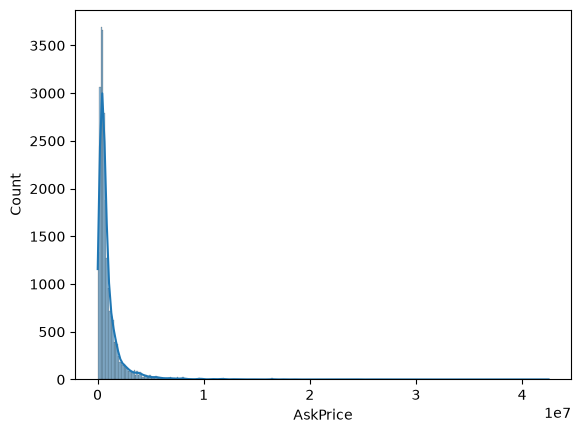

In [61]:
sns.histplot(data=df, x='AskPrice', kde=True)
plt.show()

FROM THE ABOVE I CAN SEE THAT MY ASKPRICE COLUMN IS SKEWED TO THE RIGHT, MEANING MOST CARS SIT ON THE LOWER BOUND OF THE DISTRIBUTION

In [62]:
df['AskPrice'].describe()

count    2.457500e+04
mean     1.022982e+06
std      1.615330e+06
min      1.500000e+04
25%      3.500000e+05
50%      5.800000e+05
75%      1.050000e+06
max      4.250000e+07
Name: AskPrice, dtype: float64

WE WANT TO SEE NOW WHETHER THESE PRICES ARE FOR LUXURY CARS OR THERE ARE ERRORS IN THE DATA

In [63]:
df.nlargest(10, 'AskPrice')[['Brand', 'model', 'Year', 'AskPrice']]

,Brand,model,Year,AskPrice
3331,Rolls-Royce,Phantom Series II,2015.0,42500000.0
12913,Rolls-Royce,Phantom Series II,2015.0,42500000.0
22267,Lamborghini,Urus,2021.0,39000000.0
22868,Mercedes-Benz,G Class,2023.0,34800000.0
19873,Mercedes-Benz,G Class,2024.0,30500000.0
962,Lexus,NaN,2024.0,27750000.0
10544,Lexus,NaN,2024.0,27750000.0
331,Toyota,NaN,2016.0,26400000.0
9913,Toyota,NaN,2016.0,26400000.0
811,Toyota,G,2019.0,26000000.0


I CAN SEE THAT MOST OF THESE CARS THAT ARE AFFECTING MY DISTRIBUTION ARE ACTUALLY EXPENSIVE CARS

In [64]:
threshold = df['AskPrice'].quantile(0.99)

print("99th percentile:", threshold)

print(
    "Prices above the 99th percentile:",
    (df['AskPrice'] > threshold).sum()
)

99th percentile: 7619499.99999988
Prices above the 99th percentile: 246



FROM THIS I CAN SEE THAT 246 LISTSINGS HAVE PRICES ABOVE THE 99TH PERCENTILE CUTOFF. THE EXACT AMOUNT MAY DIFFER THOUGH AS 1% OF ALL ROWS HAVE MISSING VALUES

In [65]:
threshold = df['AskPrice'].quantile(0.99)

high_price_cars = df.loc[
    df['AskPrice'] > threshold,
    ['Brand', 'model', 'Year', 'AskPrice']
].sort_values('AskPrice', ascending=False)

high_price_cars.head(30)

,Brand,model,Year,AskPrice
12913,Rolls-Royce,Phantom Series II,2015.0,42500000.0
3331,Rolls-Royce,Phantom Series II,2015.0,42500000.0
22267,Lamborghini,Urus,2021.0,39000000.0
22868,Mercedes-Benz,G Class,2023.0,34800000.0
19873,Mercedes-Benz,G Class,2024.0,30500000.0
962,Lexus,NaN,2024.0,27750000.0
10544,Lexus,NaN,2024.0,27750000.0
9913,Toyota,NaN,2016.0,26400000.0
331,Toyota,NaN,2016.0,26400000.0
811,Toyota,G,2019.0,26000000.0


In [66]:
df.loc[[3331, 12913]]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
3331,Rolls-Royce,Phantom Series II,2015.0,9.0,80089.393405,Automatic,second,Petrol,Aug-24,"Rolls-Royce Phantom Series II EWB, 2015, Petrol",42500000.0
12913,Rolls-Royce,Phantom Series II,2015.0,9.0,80089.393405,Automatic,second,Petrol,Aug-24,"Rolls-Royce Phantom Series II EWB, 2015, Petrol",42500000.0


In [67]:
df.loc[3331].equals(df.loc[12913])

True

In [68]:
df.duplicated().sum()

np.int64(9830)

FROM THE CODE ABOVE I WAS CHECKING TO SEE WHETHER THE HIGH DEGREE OF SKEWENESS WAS AS A RESULT OF DUPLICATES, AND I FOUND THAT IT PARTLY IS

In [69]:
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum())

Dataset shape: (24575, 11)

Missing values per column:
Brand             263
model             452
Year              309
Age                96
kmDriven            0
Transmission        0
Owner           10584
FuelType            0
PostedDate       6214
AdditionInfo        0
AskPrice            0
dtype: int64


In [70]:
df = df.drop_duplicates().copy()

I DECIDED TO REMOVE THE DUPLICATES, AND CREATED A COPY OF THE RESULTANT DATAFRAME

In [71]:
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum())

Dataset shape: (14745, 11)

Missing values per column:
Brand            132
model            226
Year             155
Age               48
kmDriven           0
Transmission       0
Owner           5231
FuelType           0
PostedDate      3081
AdditionInfo       0
AskPrice           0
dtype: int64


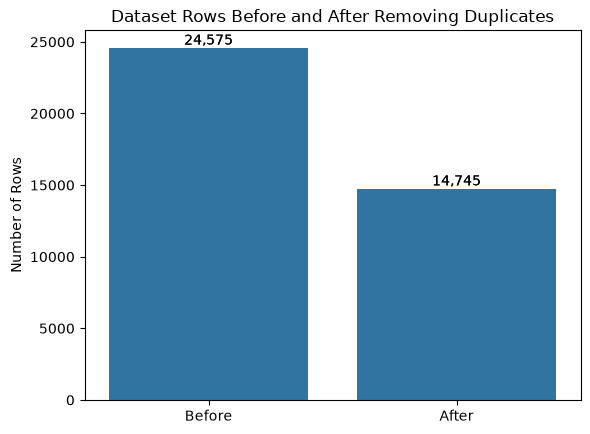

Duplicates removed: 9830


In [72]:
before_rows = 24575
after_rows = 14745

plt.figure()

ax = sns.barplot(
    x=['Before', 'After'],
    y=[before_rows, after_rows]
)

plt.title('Dataset Rows Before and After Removing Duplicates')
plt.ylabel('Number of Rows')

for i, value in enumerate([before_rows, after_rows]):
    ax.bar_label(ax.containers[0], fmt='{:,.0f}')

plt.show()

print("Duplicates removed:", before_rows - after_rows)

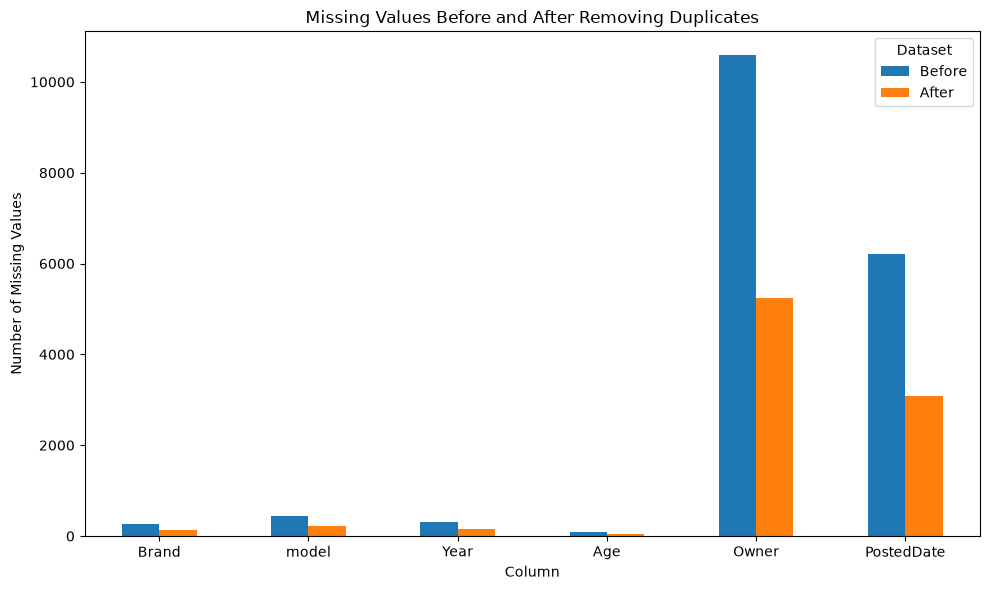

In [73]:
missing_before = pd.Series({
    'Brand': 263,
    'model': 452,
    'Year': 309,
    'Age': 96,
    'Owner': 10584,
    'PostedDate': 6214
})

missing_after = pd.Series({
    'Brand': 132,
    'model': 226,
    'Year': 155,
    'Age': 48,
    'Owner': 5231,
    'PostedDate': 3081
})

missing_comparison = pd.DataFrame({
    'Before': missing_before,
    'After': missing_after
})

ax = missing_comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

ax.set_title('Missing Values Before and After Removing Duplicates')
ax.set_xlabel('Column')
ax.set_ylabel('Number of Missing Values')
plt.xticks(rotation=0)
plt.legend(title='Dataset')
plt.tight_layout()
plt.show()

THIS IS A VISUALISATION OF EVERY COLUMN BEFORE AND AFTER REMOVING THE DUPLICATED ROWS FROM THE DATASET

In [74]:
df['AskPrice'].skew()

np.float64(8.144025336887008)

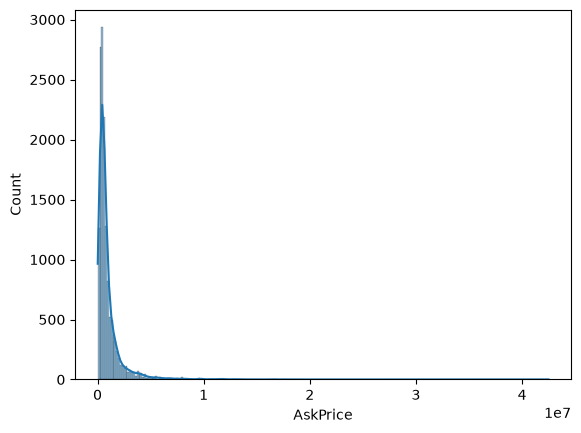

In [75]:
sns.histplot(data=df, x='AskPrice', kde=True)
plt.show()

AFTER EFFORTS OF TRYING TO REDUCE THE SKEWENESS IN THE DATASET, IT ONLY INCREASED THE SKEWENESS EVEN FURTHER

Original skewness: 8.144025336887008
Log skewness: 0.3896448002575816


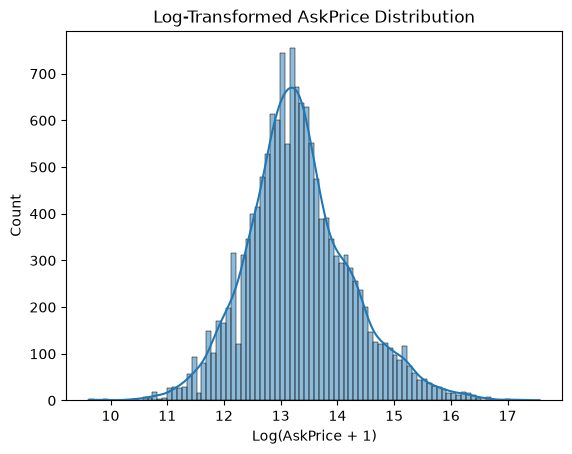

In [76]:
df['AskPrice_log'] = np.log1p(df['AskPrice'])

print("Original skewness:", df['AskPrice'].skew())
print("Log skewness:", df['AskPrice_log'].skew())

sns.histplot(df['AskPrice_log'], kde=True)
plt.title('Log-Transformed AskPrice Distribution')
plt.xlabel('Log(AskPrice + 1)')
plt.show()

In [77]:
df['AskPrice_log'].skew()

np.float64(0.3896448002575816)


I THEN DECIDED TO APPLY LOG TRANSFORMATION TO COMPRESS THE LARGE PRICES MORE THAN SMALLER ONE TO REDUCE SKEWENESS, AND IT WORKED MY DATA IS NOW NORMALLY DISTRIBUTED. 
THE SKEW FUNCTION IS ALSO CLOSE TO ZERO NOW

In [78]:
df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,AskPrice_log
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0,12.180760
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,12.834684
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,12.128111
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Diesel,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,13.244583
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,13.437176
...,...,...,...,...,...,...,...,...,...,...,...,...
24570,Maruti Suzuki,Wagon-R,2022.0,2.0,31000.000000,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0,13.262127
24571,BMW,X1,2017.0,7.0,45000.000000,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0,14.111905
24572,Maruti Suzuki,New-gen Swift,2011.0,13.0,60000.000000,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0,11.982935
24573,Tata,Zest,2019.0,5.0,62000.000000,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0,12.847929


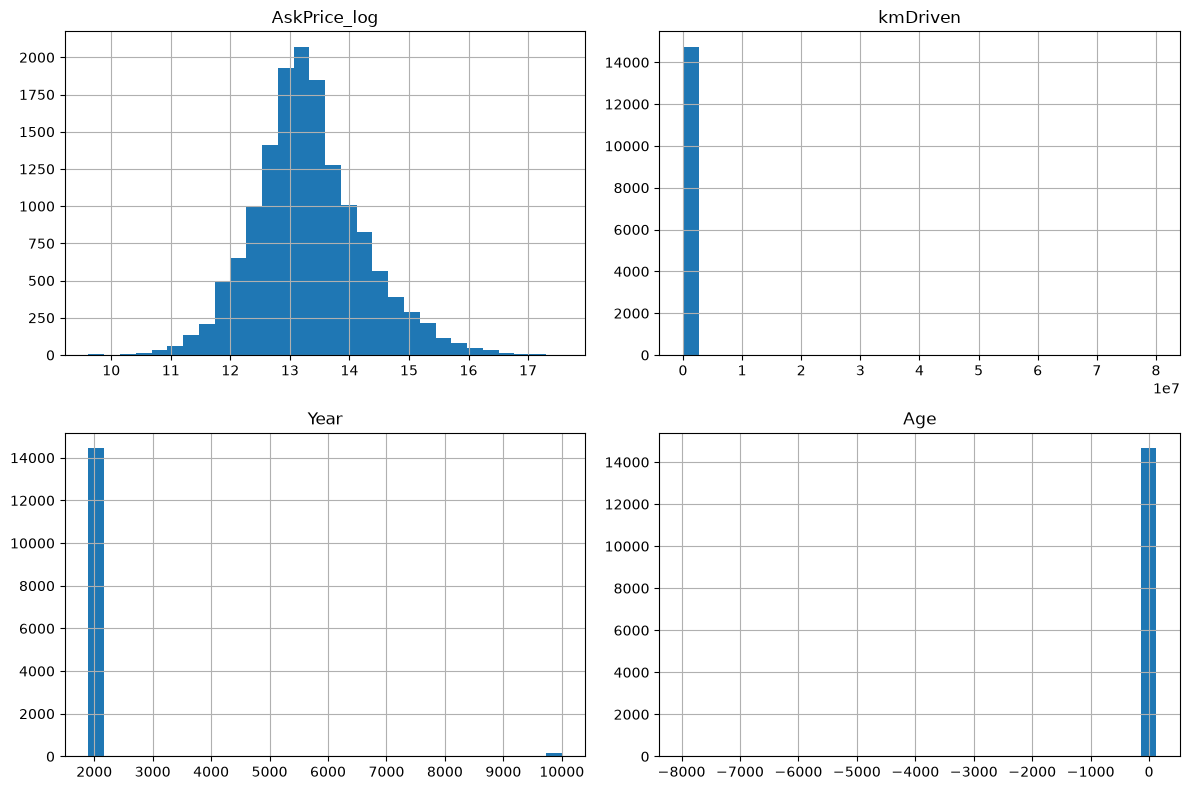

In [79]:
numerical_cols = ['AskPrice_log', 'kmDriven', 'Year', 'Age']

df[numerical_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

FROM THIS VISUALISATION I CAN TELL THAT ALL OF MY NUMERICAL COLUMNS ARE SKEWED, I WILL APPLY LOG THE KMDRIVEN AS APPLYING IT TO THE THE AGE AND YEAR COLUMNS MAY AFFECT

In [80]:
df['kmDriven_log'] = np.log1p(df['kmDriven'])

df[['AskPrice_log', 'kmDriven_log']].skew()

AskPrice_log    0.389645
kmDriven_log   -5.340184
dtype: float64

FROM THESE FIGURES I CAN SEE THAT THERE IS SOMETHING WRONG WITH THE KMDRIVEN LOG TRASNFORMATION AS IT GOES BELOW ZERO NOW

In [81]:
df['kmDriven'].describe()

count    1.474500e+04
mean     7.886535e+04
std      6.609203e+05
min      0.000000e+00
25%      5.000000e+04
50%      7.500000e+04
75%      8.100000e+04
max      8.006100e+07
Name: kmDriven, dtype: float64

Original skewness: 120.22361223228879
Log skewness: -5.340183686384962


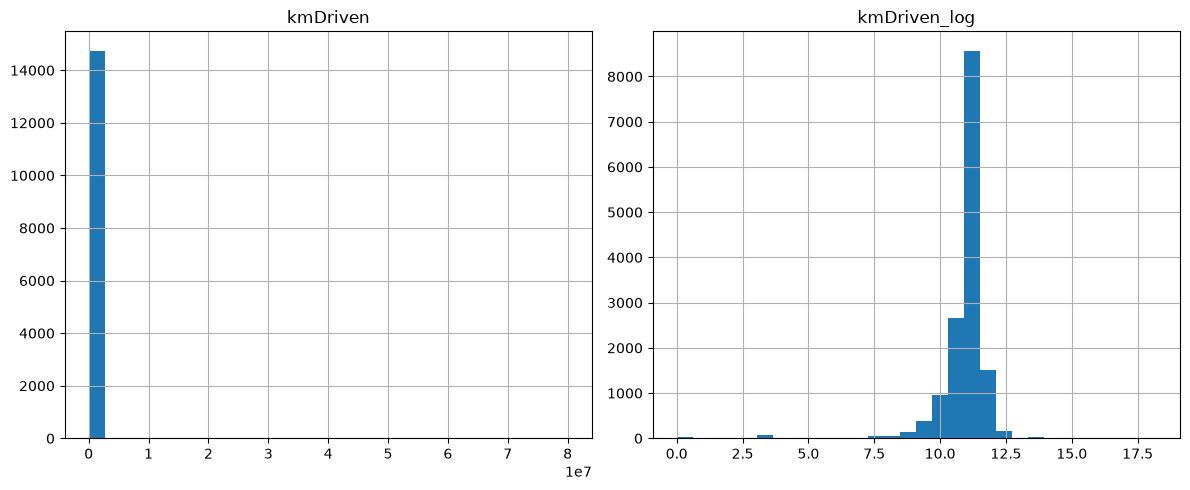

In [82]:
print("Original skewness:", df['kmDriven'].skew())
print("Log skewness:", df['kmDriven_log'].skew())

df[['kmDriven', 'kmDriven_log']].hist(
    figsize=(12, 5),
    bins=30
)

plt.tight_layout()
plt.show()

THIS VISUALISATION SHOW THE DIFFERENCE IN THE KMDRIVEN BEFORE AND AFTER THE KLMDRIVEN FEATURE, AFTER APPLYING THE FEATURE THE SKEWENESS GOT REDUCED

In [83]:
df['kmDriven'].value_counts().sort_index().head(15)

kmDriven
0.0     30
1.0      7
2.0      1
3.0      2
4.0      1
10.0     4
12.0     1
15.0     5
16.0     3
18.0     3
19.0     1
20.0     5
22.0     7
23.0     4
24.0     1
Name: count, dtype: int64

In [84]:
df.nlargest(10, 'kmDriven')[
    ['Brand', 'model', 'Year', 'kmDriven', 'AskPrice', 'AdditionInfo']
]

,Brand,model,Year,kmDriven,AskPrice,AdditionInfo
8731,Toyota,Alto-800,9999.0,80061000.0,230000.0,Maruti Suzuki Alto 800 61000 Km Driven and exc...
451,Hyundai,i10,9999.0,1040000.0,200000.0,Hyundai i10 40000 Km Driven
4768,Maruti Suzuki,Alto,2019.0,980000.0,310000.0,Maruti Suzuki Alto 800 2019 CNG & Hybrids 9800...
7529,Toyota,Innova,2012.0,980000.0,850000.0,Toyota Innova 2012 Diesel 980000 Km Driven
7738,Chevrolet,Cruze,2012.0,950000.0,350000.0,Chevrolet Cruze 2012 Diesel Well Maintained
22845,Hyundai,Accent,2011.0,950000.0,140000.0,Accent Hyundai good condition
24493,Honda,Amaze,2018.0,950000.0,320000.0,Honda amaze 2018 cng Bilkul ok kondition gadi ...
21031,Maruti Suzuki,Swift-Dzire-Tour,2022.0,901500.0,690000.0,Maruti Suzuki Swift Dzire Tour 2022
22696,Maruti Suzuki,Eeco,2019.0,900000.0,345000.0,Maruti Suzuki Eeco 2019 CNG & Hybrids 900000 K...
2222,Mercedes-Benz,G,2016.0,850000.0,2600000.0,"Mercedes-Benz GLE Class 2.1 250d 4MATIC, 2016,..."


THIS REVEALED SOME OF THE UNDERLYING REASONS THAT AFFECTED OUR DATA AND MADE IT SKEW

In [85]:
print("Original skewness:", df['kmDriven'].skew())
print("Log skewness:", df['kmDriven_log'].skew())

print("Mileage above 200,000 km:",
      (df['kmDriven'] > 200_000).sum())

print("Mileage above 500,000 km:",
      (df['kmDriven'] > 500_000).sum())

Original skewness: 120.22361223228879
Log skewness: -5.340183686384962
Mileage above 200,000 km: 155
Mileage above 500,000 km: 48


THIS SHOW THE DISTRIBUTION BEFORE AND AFTER THE LOG AND WHAT RANGE OF KILOMETERS IS AFFECTING THE DATASET THE MOST

In [86]:
df.loc[[8731, 451, 7529], ['kmDriven', 'AdditionInfo']]

,kmDriven,AdditionInfo
8731,80061000.0,Maruti Suzuki Alto 800 61000 Km Driven and exc...
451,1040000.0,Hyundai i10 40000 Km Driven
7529,980000.0,Toyota Innova 2012 Diesel 980000 Km Driven


I SINGLED OUT THE DATA WHICH WAS INCORRECT SO I CAN APPLY THE NECESSARY TECHNIQUES TO RECTIFY IT

In [87]:

df['km_from_info'] = (
    df['AdditionInfo']
    .str.extract(r'(\d[\d,]*)\s*km\b', expand=False)
    .str.replace(',', '', regex=False)
)

df['km_from_info'] = pd.to_numeric(
    df['km_from_info'], errors='coerce'
)

mask = (
    df['km_from_info'].notna()
    & df['kmDriven'].notna()
    & (df['km_from_info'] != df['kmDriven'])
)

mismatches = df.loc[
    mask,
    ['Brand', 'model', 'Year', 'kmDriven',
     'km_from_info', 'AdditionInfo']
]

print("Rows with mileage extracted:",
      df['km_from_info'].notna().sum())
print("Potential mismatches:", len(mismatches))

display(mismatches.head(30))

Rows with mileage extracted: 20
Potential mismatches: 5


,Brand,model,Year,kmDriven,km_from_info,AdditionInfo
7232,Maruti Suzuki,Ritz,2010.0,74000.0,72000.0,Ritz LXI 2010 model convert into VXI 72000km d...
9349,Toyota,NaN,NaN,30.0,65500.0,65500 km sento car
19553,Maruti Suzuki,Alto-800,2016.0,18000.0,19230.0,2016 Alto800 Lxi Full Original run 19230km on ...
19867,Honda,Amaze,2020.0,88000.0,30.0,"Honda Amaze VX(Petrol+CNG), Top Model features..."
22682,Tata,Tigor,2018.0,95000.0,30.0,Tata Tigor XM optional diesel well maintained ...


THIS CODE EXTRACTS VALUES SUCH AS 61000 KM DRIVEN AND 40,000 FROM 40000 KM DRIVEN. IT THE SHOW US THE VALUES WE EXTRACTED AND POTENTIAL MISMATCH

In [88]:
for idx in [7232, 9349, 19553, 19867, 22682]:
    print(f"\nIndex: {idx}")
    print("Current mileage:", df.loc[idx, 'kmDriven'])
    print("Description:", df.loc[idx, 'AdditionInfo'])


Index: 7232
Current mileage: 74000.0
Description: Ritz LXI 2010 model convert into VXI 72000km driven

Index: 9349
Current mileage: 30.0
Description: 65500 km sento car

Index: 19553
Current mileage: 18000.0
Description: 2016 Alto800 Lxi Full Original run 19230km on record Price fixed

Index: 19867
Current mileage: 88000.0
Description: Honda Amaze VX(Petrol+CNG), Top Model features, Milage 28-30 km/kg

Index: 22682
Current mileage: 95000.0
Description: Tata Tigor XM optional diesel well maintained average 30 km per ltr


THIS CODE WILL HELP ME SEE WHERE THE MILEAGE WAS EXTRATED AND WHERE IT MAY HAVE MADE A MISTAKE

In [89]:
df.loc[9349, 'kmDriven'] = 65500

ON THIS SPECIFIC LOCATION THE FUNCTION MADE A MISTAKE WHICH NEEDED TO BE RECTIFIED

In [90]:
suspicious_km = df[
    (df['kmDriven'] < 1000) |
    (df['kmDriven'] > 500000)
].copy()

print("Suspicious rows:", len(suspicious_km))

display(
    suspicious_km[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ].sort_values('kmDriven')
)

Suspicious rows: 219


,Brand,model,Year,kmDriven,AdditionInfo
48,Maruti Suzuki,Ciaz,2018.0,0.0,"Maruti Suzuki Ciaz Smart Hybrid Alpha , 2018, ..."
21522,Mahindra,Thar Roxx,2024.0,0.0,"THAR ROXX, New THAR , XUV 3XO,XUV700, SCORPIO ..."
21119,Honda,City,2011.0,0.0,Honda City 2011 CNG &r Hybrids Well Maintained
20548,Maruti Suzuki,Alto-800,2024.0,0.0,Garage shedl for sale
19844,Tata,tata-punch,2024.0,0.0,"Tata Punch Accomplished Dazzle Sunroof CNG, 20..."
...,...,...,...,...,...
7738,Chevrolet,Cruze,2012.0,950000.0,Chevrolet Cruze 2012 Diesel Well Maintained
7529,Toyota,Innova,2012.0,980000.0,Toyota Innova 2012 Diesel 980000 Km Driven
4768,Maruti Suzuki,Alto,2019.0,980000.0,Maruti Suzuki Alto 800 2019 CNG & Hybrids 9800...
451,Hyundai,i10,9999.0,1040000.0,Hyundai i10 40000 Km Driven


THIS FUNCTION FINDS AND FLAGS SUSPICIOUS MILEAGES BY LOOKING AT THE ACTUAL KM DRIVEN AND WHAT IS ON THE ADDTIONAL INFO COLUMN. FROM THE INFORMATION I FOUND I CAN SEE THERE IS A LOT I WILL HAVE TO INVESTIGATE

THERE WILL BE A SERIES OF STEPS TAKEN TO FIND THE SOLUTION

In [91]:
print("Zero mileage:", (df['kmDriven'] == 0).sum())

print("Below 1,000 km:",
      ((df['kmDriven'] > 0) & (df['kmDriven'] < 1000)).sum())

print("Above 200,000 km:",
      (df['kmDriven'] > 200_000).sum())

print("Above 500,000 km:",
      (df['kmDriven'] > 500_000).sum())

print("Above 1,000,000 km:",
      (df['kmDriven'] > 1_000_000).sum())

Zero mileage: 30
Below 1,000 km: 141
Above 200,000 km: 155
Above 500,000 km: 48
Above 1,000,000 km: 2


FOR STEP 1 I BROKE DOWN THE 220 ROWS BY FINDING THE LOW-MILEAGE AND HIGH-MILEAGES

In [92]:
zero_km = df[df['kmDriven'] == 0]

display(
    zero_km[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ].head(20)
)

,Brand,model,Year,kmDriven,AdditionInfo
48,Maruti Suzuki,Ciaz,2018.0,0.0,"Maruti Suzuki Ciaz Smart Hybrid Alpha , 2018, ..."
508,Mahindra,Jeep,1994.0,0.0,"Mahindra Jeep Commander 750 DI, 1994, Diesel"
5346,Mahindra,Scorpio N,2024.0,0.0,"Mahindra Scorpio N Z2 Diesel MT 7 STR, 2024, D..."
7507,Toyota,NaN,2024.0,0.0,Hath gadi thella new juice set-up thella
7622,Mahindra,Jeep,1994.0,0.0,"Mahindra Jeep, 1994, Diesel"
7990,Maruti Suzuki,Wagon-R,2018.0,0.0,WagonR 2018
8352,Mahindra,XUV300,2024.0,0.0,"Mahindra XUV300 W2 1.2 Petrol, 2024, Petrol"
8564,Hyundai,Santro,2003.0,0.0,Hyundai Santro 2003 CNG & Hybrids Good Condition
9093,Toyota,CERATO,2024.0,0.0,Kia CERATO 2024
9550,Tata,NaN,NaN,0.0,Tata safari with good condition


FOR STEP 2 I INVESTIGATED THE ZERO KM MILEAGES

In [93]:
zero_km = df[df['kmDriven'] == 0]

zero_km[
    zero_km['AdditionInfo'].str.contains(
        r'\b0\s*km\b|\bzero\s*km\b',
        case=False,
        na=False,
        regex=True
    )
][['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']]

,Brand,model,Year,kmDriven,AdditionInfo
22324,Hyundai,Aura,2024.0,0.0,Hyundai Aura 2024 CNG & Hybrids 0 Km Driven


FOR STEP 3 I DISTINGUISHED BETWEEN ZERO KM MILEAGE AND MISSING MILEAGUES, WHICH WILL GIVE US STRONGER EVIDENCE THAN ASSUMIMG EVERY ZERO KM IS A ZERO

In [94]:
zero_km = df[df['kmDriven'] == 0]

explicit_zero = zero_km['AdditionInfo'].str.contains(
    r'\b0\s*km\b|\bzero\s*km\b',
    case=False,
    na=False,
    regex=True
)

remaining_zero = zero_km[~explicit_zero]

display(
    remaining_zero[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ]
)

,Brand,model,Year,kmDriven,AdditionInfo
48,Maruti Suzuki,Ciaz,2018.0,0.0,"Maruti Suzuki Ciaz Smart Hybrid Alpha , 2018, ..."
508,Mahindra,Jeep,1994.0,0.0,"Mahindra Jeep Commander 750 DI, 1994, Diesel"
5346,Mahindra,Scorpio N,2024.0,0.0,"Mahindra Scorpio N Z2 Diesel MT 7 STR, 2024, D..."
7507,Toyota,NaN,2024.0,0.0,Hath gadi thella new juice set-up thella
7622,Mahindra,Jeep,1994.0,0.0,"Mahindra Jeep, 1994, Diesel"
7990,Maruti Suzuki,Wagon-R,2018.0,0.0,WagonR 2018
8352,Mahindra,XUV300,2024.0,0.0,"Mahindra XUV300 W2 1.2 Petrol, 2024, Petrol"
8564,Hyundai,Santro,2003.0,0.0,Hyundai Santro 2003 CNG & Hybrids Good Condition
9093,Toyota,CERATO,2024.0,0.0,Kia CERATO 2024
9550,Tata,NaN,NaN,0.0,Tata safari with good condition


AFTER STEP 3 I WANT TO FOCUS ON THE OTHER VALUES WHICH ARE UNKNOWN AND DECIDE WHETHER THERE ARE MISTAKES THERE OR THEY ARE GENUINE ZEROS

FROM THE OUTPUT I CAN SEE THAT MOST DESRIPTION DON'T SPECIFY THE KM OF THE CAR

In [95]:
check_indices = [7507, 9550, 20548, 9093, 20262, 23925, 24227]

print(
    df.loc[
        check_indices,
        ['Brand', 'model', 'Year', 'kmDriven', 'AskPrice', 'AdditionInfo']
    ].to_string()
)

               Brand         model    Year  kmDriven   AskPrice                                            AdditionInfo
7507          Toyota           NaN  2024.0       0.0    32000.0                Hath gadi thella new juice set-up thella
9550            Tata           NaN     NaN       0.0   290000.0                         Tata safari with good condition
20548  Maruti Suzuki      Alto-800  2024.0       0.0   280000.0                                   Garage shedl for sale
9093          Toyota        CERATO  2024.0       0.0    45000.0                                         Kia CERATO 2024
20262  Maruti Suzuki  Grand Vitara  2024.0       0.0  3400000.0                INVICTO ALPHA+ full onroad price 3400000
23925  Maruti Suzuki       Wagon-R  2013.0       0.0   250000.0  Maruti Suzuki Wagon R 2013 CNG & Hybrids 000 Km Driven
24227  Maruti Suzuki        Brezza  2024.0       0.0    29000.0                       Fujifilm XT-200 WITH FUJI 15-45MM


FROM THE INFORMATION ABOVE I CAN IDENTIFY COLUMNS THAT ARE IRRELEVANT WHICH ARE [7507, 20548, 24227] AS THEY HAVE DATA QUALITY ISSUES

In [96]:
# 1. Listings that are clearly not cars
irrelevant_indices = [7507, 20548, 24227]

# 2. Impossible/future vehicle years
invalid_year = df['Year'].notna() & (
    (df['Year'] < 1950) | (df['Year'] > 2026)
)

# 3. Invalid target prices
invalid_price = df['AskPrice'].isna() | (df['AskPrice'] <= 0)

print("Irrelevant listings:", df.index.isin(irrelevant_indices).sum())
print("Invalid vehicle years:", invalid_year.sum())
print("Invalid prices:", invalid_price.sum())

Irrelevant listings: 3
Invalid vehicle years: 140
Invalid prices: 0


THIS CODE LOOKS AT LISTINGS THAT ARE NOT CARS, IMPOSSIBLE VEHICLE YEARS AND INVALID TARGET PRICES AND THEN RETURN A TOTAL COUNT

In [97]:
high_mileage = df[df['kmDriven'] > 500_000]

display(
    high_mileage[
        ['Brand', 'model', 'Year', 'kmDriven', 'AskPrice', 'AdditionInfo']
    ].head(20)
)

,Brand,model,Year,kmDriven,AskPrice,AdditionInfo
451,Hyundai,i10,9999.0,1040000.0,200000.0,Hyundai i10 40000 Km Driven
595,Tata,Tigor,2018.0,800000.0,485000.0,"Tata Tigor 1.2 Revotron XT, 2018, Petrol"
634,Renault,Duster,2015.0,760045.0,155000.0,Renault Duster 2015 Diesel 760045 Km Driven
1387,NaN,Nexon,2020.0,775000.0,895000.0,Nexon 2020 diesel xm october model like new ve...
1704,Kia,NaN,NaN,730000.0,930000.0,Top model kua sonet
2166,Maruti Suzuki,Swift,2020.0,750000.0,520000.0,Maruti Suzuki Swift Dzire 2020 Diesel 750000 K...
2222,Mercedes-Benz,G,2016.0,850000.0,2600000.0,"Mercedes-Benz GLE Class 2.1 250d 4MATIC, 2016,..."
3267,Mitsubishi,Pajero Sport,2015.0,850000.0,875000.0,"Mitsubishi Pajero Sport 2.5 Automatic, 2015, D..."
3463,Maruti Suzuki,Alto-800,2017.0,700000.0,200000.0,Just buying
3984,Mahindra,Scorpio,2017.0,710205.0,875000.0,"Mahindra Scorpio S4, 2017, Diesel"


THIS CODE LOOKS AT EXTREME MILEAGES AND FROM THE OUTPUT I CAN SEE SOEM MILEAGES ARE EXTREME WHILE OTHERS ARE INCORRECT RECORDINGS

In [98]:
df.loc[df['Year'] == 9999, 'Year'] = np.nan

print("Remaining Year = 9999:", (df['Year'] == 9999).sum())
print("Missing Year values:", df['Year'].isna().sum())

Remaining Year = 9999: 0
Missing Year values: 292


In [99]:
print(
    df.loc[
        [451, 4768],
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ].to_string()
)

              Brand model    Year   kmDriven                                                AdditionInfo
451         Hyundai   i10     NaN  1040000.0                                 Hyundai i10 40000 Km Driven
4768  Maruti Suzuki  Alto  2019.0   980000.0  Maruti Suzuki Alto 800 2019 CNG & Hybrids 980000 Km Driven


In [100]:
df.loc[451, 'kmDriven'] = 40000

# Verify the correction
print(df.loc[451, ['Year', 'kmDriven', 'AdditionInfo']])

Year                                    NaN
kmDriven                            40000.0
AdditionInfo    Hyundai i10 40000 Km Driven
Name: 451, dtype: object


FROM THE CODE ABOVE I RECTIFIED THE YEAR VALUES WHICH HAD IMPOSSIBLE YEAR OF 9999, AND THEN I IDENTIDIED THE COLUMNS WHICH HAD SUSPICIOUS RECORDING THE FIXED THE ISSUE FROM THE OUTPUT THAT I OBSERVED

In [101]:
high_mileage = df[df['kmDriven'] > 500_000]

print(
    high_mileage[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ].head(20).to_string()
)

              Brand         model    Year  kmDriven                                                          AdditionInfo
595            Tata         Tigor  2018.0  800000.0                              Tata Tigor 1.2 Revotron XT, 2018, Petrol
634         Renault        Duster  2015.0  760045.0                           Renault Duster 2015 Diesel 760045 Km Driven
1387            NaN         Nexon  2020.0  775000.0                   Nexon 2020 diesel xm october model like new vehicle
1704            Kia           NaN     NaN  730000.0                                                   Top model kua sonet
2166  Maruti Suzuki         Swift  2020.0  750000.0                Maruti Suzuki Swift Dzire 2020 Diesel 750000 Km Driven
2222  Mercedes-Benz             G  2016.0  850000.0                 Mercedes-Benz GLE Class 2.1 250d 4MATIC, 2016, Diesel
3267     Mitsubishi  Pajero Sport  2015.0  850000.0                   Mitsubishi Pajero Sport 2.5 Automatic, 2015, Diesel
3463  Maruti Suzuki     

I CONTINUED TO INVESTIGATE VALUES THAT ARE HIGH MILEAGUE TO IDENTIFY MORE POTENTIAL DISCREPANCIES, WHICH I FOUND MORE VALUES THAT WERE INCORRECT

In [102]:
df['km_from_info'] = (
    df['AdditionInfo']
    .str.extract(r'(\d[\d,]*)\s*km\b', expand=False)
    .str.replace(',', '', regex=False)
)

df['km_from_info'] = pd.to_numeric(
    df['km_from_info'], errors='coerce'
)

mismatches = df[
    df['km_from_info'].notna()
    & df['kmDriven'].notna()
    & (df['km_from_info'] != df['kmDriven'])
]

print(
    mismatches[
        ['Brand', 'model', 'Year', 'kmDriven',
         'km_from_info', 'AdditionInfo']
    ].to_string()
)

               Brand     model    Year  kmDriven  km_from_info                                                         AdditionInfo
7232   Maruti Suzuki      Ritz  2010.0   74000.0       72000.0                  Ritz LXI 2010 model convert into VXI 72000km driven
19553  Maruti Suzuki  Alto-800  2016.0   18000.0       19230.0     2016 Alto800 Lxi Full Original run 19230km on record Price fixed
19867          Honda     Amaze  2020.0   88000.0          30.0   Honda Amaze VX(Petrol+CNG), Top Model features, Milage 28-30 km/kg
22682           Tata     Tigor  2018.0   95000.0          30.0  Tata Tigor XM optional diesel well maintained average 30 km per ltr


THIS CODE FINDS MILEAGES THAT CONTRADICT WITH THE ADDITIONAL INFO COLUMN, THE CODE SHOWS THE DISCREPANCIES IN THE OUTPUT

In [103]:
df.loc[9349, 'kmDriven'] = 65500

print(df.loc[9349, ['kmDriven', 'km_from_info', 'AdditionInfo']])

kmDriven                   65500.0
km_from_info               65500.0
AdditionInfo    65500 km sento car
Name: 9349, dtype: object


THIS CODE CORRECTS THE MISTAKEN MILEAGE

In [104]:
fuel_efficiency = df['AdditionInfo'].str.contains(
    r'km\s*/\s*kg|km\s+per\s+litre',
    case=False,
    na=False,
    regex=True
)

mismatches = df[
    df['km_from_info'].notna()
    & df['kmDriven'].notna()
    & (df['km_from_info'] != df['kmDriven'])
    & ~fuel_efficiency
]

print(
    mismatches[
        ['Brand', 'model', 'Year', 'kmDriven',
         'km_from_info', 'AdditionInfo']
    ].to_string()
)

               Brand     model    Year  kmDriven  km_from_info                                                         AdditionInfo
7232   Maruti Suzuki      Ritz  2010.0   74000.0       72000.0                  Ritz LXI 2010 model convert into VXI 72000km driven
19553  Maruti Suzuki  Alto-800  2016.0   18000.0       19230.0     2016 Alto800 Lxi Full Original run 19230km on record Price fixed
22682           Tata     Tigor  2018.0   95000.0          30.0  Tata Tigor XM optional diesel well maintained average 30 km per ltr


In [105]:
df.loc[19553, 'kmDriven'] = 19230

# Verify
print(df.loc[19553, ['kmDriven', 'AdditionInfo']])

kmDriven                                                  19230.0
AdditionInfo    2016 Alto800 Lxi Full Original run 19230km on ...
Name: 19553, dtype: object


THE CODE IMPROVES THE IMPROVES MISTAKE DETECTION BY REMOVING THE DESCRIPTION SUCH AS KM/KG, WHICH HELPED ME IDENTIFY ONE WHCIH I CORRECTED

In [106]:

print(df['kmDriven'].describe())

print("Skewness:", df['kmDriven'].skew())

print("Median:", df['kmDriven'].median())

count    1.474500e+04
mean     7.880206e+04
std      6.608727e+05
min      0.000000e+00
25%      5.000000e+04
50%      7.500000e+04
75%      8.100000e+04
max      8.006100e+07
Name: kmDriven, dtype: float64
Skewness: 120.24969465714358
Median: 75000.0


WHEN I FURTHER INVESTIGATE THE KM DRIVEN I CAN SEE THERE IS STILL ALOT OF OUTLIERS THAT AFFECT THE DISTRIBUTION OF THIS DATA

In [107]:
display(
    df.nlargest(10, 'kmDriven')[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ]
)

,Brand,model,Year,kmDriven,AdditionInfo
8731,Toyota,Alto-800,NaN,80061000.0,Maruti Suzuki Alto 800 61000 Km Driven and exc...
4768,Maruti Suzuki,Alto,2019.0,980000.0,Maruti Suzuki Alto 800 2019 CNG & Hybrids 9800...
7529,Toyota,Innova,2012.0,980000.0,Toyota Innova 2012 Diesel 980000 Km Driven
7738,Chevrolet,Cruze,2012.0,950000.0,Chevrolet Cruze 2012 Diesel Well Maintained
22845,Hyundai,Accent,2011.0,950000.0,Accent Hyundai good condition
24493,Honda,Amaze,2018.0,950000.0,Honda amaze 2018 cng Bilkul ok kondition gadi ...
21031,Maruti Suzuki,Swift-Dzire-Tour,2022.0,901500.0,Maruti Suzuki Swift Dzire Tour 2022
22696,Maruti Suzuki,Eeco,2019.0,900000.0,Maruti Suzuki Eeco 2019 CNG & Hybrids 900000 K...
2222,Mercedes-Benz,G,2016.0,850000.0,"Mercedes-Benz GLE Class 2.1 250d 4MATIC, 2016,..."
3267,Mitsubishi,Pajero Sport,2015.0,850000.0,"Mitsubishi Pajero Sport 2.5 Automatic, 2015, D..."


In [108]:
df.loc[8731, 'kmDriven'] = 61000

# Verify the correction
print(df.loc[8731, ['kmDriven', 'AdditionInfo']])

kmDriven                                                  61000.0
AdditionInfo    Maruti Suzuki Alto 800 61000 Km Driven and exc...
Name: 8731, dtype: object


AFTER LOOKING AT THE 10 HIGHEST ROWS ON THE KM DRIVEN ROW, I IDENTIFIED ONE WHICH HAD THE HIGHEST VALUE AND CORRECTED THE ERROR

In [109]:
print(df['kmDriven'].describe())
print("Skewness:", df['kmDriven'].skew())
print("Median:", df['kmDriven'].median())

count     14745.000000
mean      73376.490835
std       53306.546657
min           0.000000
25%       50000.000000
50%       75000.000000
75%       81000.000000
max      980000.000000
Name: kmDriven, dtype: float64
Skewness: 7.595480528064047
Median: 75000.0


THE STATS HAVE IMPROVED AFTER CORRECTING THE MISTAKE

In [110]:
Q1 = df['kmDriven'].quantile(0.25)
Q3 = df['kmDriven'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[
    (df['kmDriven'] < lower_bound) |
    (df['kmDriven'] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Q1: 50000.0
Q3: 81000.0
IQR: 31000.0
Lower bound: 3500.0
Upper bound: 127500.0
Number of potential outliers: 1108


THIS CODE CHECKS POTENTIAL OUTLIERS, FROM THE OUTPUT I CAN SEE THAT 3,500 KM OR ABOVE 127,500 KM IS FLAGGED

In [111]:
low_outliers = df[df['kmDriven'] < lower_bound]
high_outliers = df[df['kmDriven'] > upper_bound]

print("Low outliers:", len(low_outliers))
print("High outliers:", len(high_outliers))

print("\nHighest 15 mileage outliers:")
display(
    high_outliers.nlargest(15, 'kmDriven')[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ]
)

Low outliers: 243
High outliers: 865

Highest 15 mileage outliers:


,Brand,model,Year,kmDriven,AdditionInfo
4768,Maruti Suzuki,Alto,2019.0,980000.0,Maruti Suzuki Alto 800 2019 CNG & Hybrids 9800...
7529,Toyota,Innova,2012.0,980000.0,Toyota Innova 2012 Diesel 980000 Km Driven
7738,Chevrolet,Cruze,2012.0,950000.0,Chevrolet Cruze 2012 Diesel Well Maintained
22845,Hyundai,Accent,2011.0,950000.0,Accent Hyundai good condition
24493,Honda,Amaze,2018.0,950000.0,Honda amaze 2018 cng Bilkul ok kondition gadi ...
21031,Maruti Suzuki,Swift-Dzire-Tour,2022.0,901500.0,Maruti Suzuki Swift Dzire Tour 2022
22696,Maruti Suzuki,Eeco,2019.0,900000.0,Maruti Suzuki Eeco 2019 CNG & Hybrids 900000 K...
2222,Mercedes-Benz,G,2016.0,850000.0,"Mercedes-Benz GLE Class 2.1 250d 4MATIC, 2016,..."
3267,Mitsubishi,Pajero Sport,2015.0,850000.0,"Mitsubishi Pajero Sport 2.5 Automatic, 2015, D..."
9411,Honda,G,2013.0,850000.0,Honda Amaze 2013 CNG & Hybrids Well Maintained


THIS CODE CHECKS HOW THE MILEAGE IS DISTRIBUTED. IT THEN OUTPUTS THE COUNT OF THE ONES ON THE LOW END AND HIGH END. AND THE HIGHEST ONES ACTUAL DATASET

In [112]:
low_outliers = df[df['kmDriven'] < lower_bound]

print(
    low_outliers[
        ['Brand', 'model', 'Year', 'kmDriven', 'AdditionInfo']
    ].sort_values('kmDriven').head(20).to_string()
)

               Brand         model    Year  kmDriven                                                         AdditionInfo
23004         Toyota      VELLFIRE  2024.0       0.0                                                 Toyota VELLFIRE 2024
24277  Maruti Suzuki       Wagon-R  2017.0       0.0                       Maruti Suzuki Wagon R VXI, 2017, CNG & Hybrids
19676        Hyundai          Aura  2024.0       0.0                                                Hyundai new Aura texy
19352  Maruti Suzuki        Fronx   2023.0       0.0                                             Maruti Suzuki Fronx 2023
9550            Tata           NaN     NaN       0.0                                      Tata safari with good condition
23925  Maruti Suzuki       Wagon-R  2013.0       0.0               Maruti Suzuki Wagon R 2013 CNG & Hybrids 000 Km Driven
24227  Maruti Suzuki        Brezza  2024.0       0.0                                    Fujifilm XT-200 WITH FUJI 15-45MM
19844           Tata    

THIS CODE SHOW THE LOW END OUTLIERS ON THE ACTUAL DATASET, AND REVEALS A FEW THAT HAVE ERRORS THAT NEED TO BE REMOVED 

In [113]:
irrelevant_indices = [7507, 24227, 24534]

df = df.drop(index=irrelevant_indices).copy()

AFTER DROPPING THE IRRELEVANT COLUMNS I LOOK AT THE ZERO MILEAGE ROWS AGAIN TO FIND POTENTIAL MISTAKES THAT I MIGHT HAVE MISSED

In [114]:
zero_mileage = df[df['kmDriven'] == 0]

print(
    zero_mileage[
        ['Brand', 'model', 'Year', 'kmDriven', 'AskPrice', 'AdditionInfo']
    ].to_string()
)

               Brand           model    Year  kmDriven   AskPrice                                                        AdditionInfo
48     Maruti Suzuki            Ciaz  2018.0       0.0   500000.0                Maruti Suzuki Ciaz Smart Hybrid Alpha , 2018, Petrol
508         Mahindra            Jeep  1994.0       0.0   275000.0                        Mahindra Jeep Commander 750 DI, 1994, Diesel
5346        Mahindra       Scorpio N  2024.0       0.0  1424700.0                 Mahindra Scorpio N Z2 Diesel MT 7 STR, 2024, Diesel
7622        Mahindra            Jeep  1994.0       0.0   295000.0                                         Mahindra Jeep, 1994, Diesel
7990   Maruti Suzuki         Wagon-R  2018.0       0.0   449999.0                                                         WagonR 2018
8352        Mahindra          XUV300  2024.0       0.0   749000.0                         Mahindra XUV300 W2 1.2 Petrol, 2024, Petrol
8564         Hyundai          Santro  2003.0       0.0    5200

In [115]:
print(df['Age'].describe())

print("Skewness:", df['Age'].skew())
print("Median:", df['Age'].median())
print("Missing values:", df['Age'].isna().sum())

count    14694.000000
mean        -9.697291
std        372.156138
min      -7975.000000
25%          5.000000
50%          7.000000
75%         10.000000
max        124.000000
Name: Age, dtype: float64
Skewness: -21.35636597736457
Median: 7.0
Missing values: 48


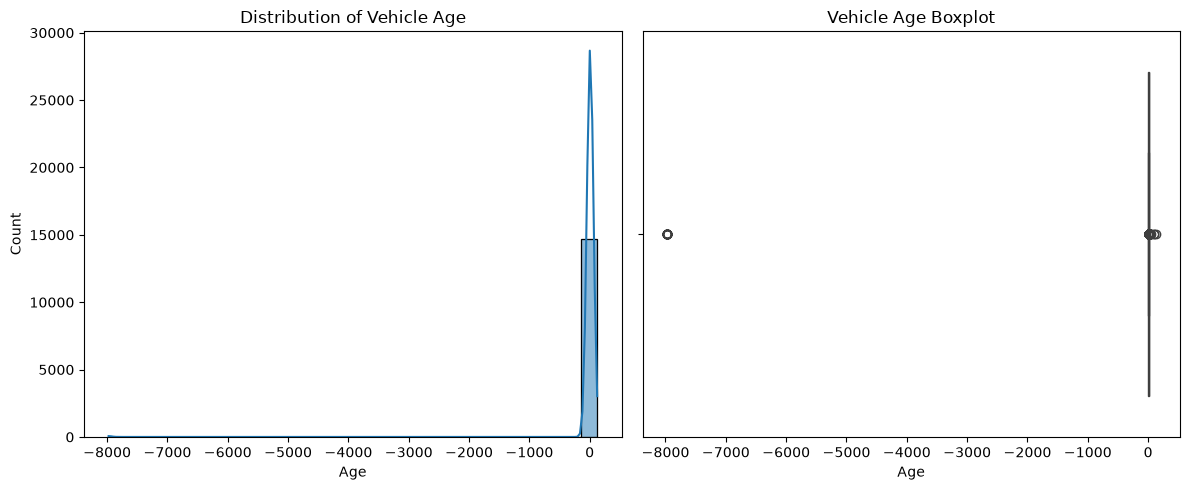

In [116]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['Age'], bins=30, kde=True, ax=ax[0])
ax[0].set_title('Distribution of Vehicle Age')

sns.boxplot(x=df['Age'], ax=ax[1])
ax[1].set_title('Vehicle Age Boxplot')

plt.tight_layout()
plt.show()

FROM THE STATS ABOVE WE CAN SEE THAT THERE ARE INCOORECT VALUES IN THE AGE KM AS THE MEAN IS -7975.000000

In [117]:
invalid_age = df[(df['Age'] < 0) | (df['Age'] > 50)]

print(
    invalid_age[
        ['Brand', 'model', 'Year', 'Age', 'AdditionInfo']
    ].sort_values('Age').to_string()
)

               Brand        model    Year     Age                                                           AdditionInfo
130          Hyundai            G     NaN -7975.0                                                         Good condition
9071   Maruti Suzuki      Wagon-R     NaN -7975.0                                              Maruti Suzuki Vagon R Car
9058          Toyota     Carnival     NaN -7975.0                         Kia Carnival Limousine In Immaculate Condition
8591             NaN         Eeco     NaN -7975.0                                                      ecco7 full okay h
8411          Toyota         City     NaN -7975.0                           Honda City vat CNG & Hybrids 51000 Km Driven
8172             NaN      Wagon-R     NaN -7975.0                                                        Parking problem
7896             NaN         Xylo     NaN -7975.0                                                No emergency urgent hai
7866             Kia          Na

FROM THE INFORMATION ABOVE I CAN ASSUME THAT THE ISSUE STEMS FROM THE WAY I IMPUTED MY MISSING VALUES ON THE AGE COLUMN

In [118]:
print(current_year)

2024.0


In [119]:
df.loc[
    (df['Age'] < 0) & (df['Year'].isna()),
    'Age'
] = np.nan

In [120]:
print("Negative ages:", (df['Age'] < 0).sum())
print("Missing ages:", df['Age'].isna().sum())

print(df['Age'].describe())

Negative ages: 0
Missing ages: 80
count    14662.000000
mean         7.687082
std          4.359989
min          0.000000
25%          5.000000
50%          7.000000
75%         10.000000
max        124.000000
Name: Age, dtype: float64


I REMOVED THE VALUES WHICH WHERE LOWER THAT 0 SO AS THEY WERE MESSING THE STATS, AND IT FIXED THE ISSUE AND THE STATS MAKE SENSE NOW. HOWEVER THERE IS STILL A HUGE OUTLIER WHERE THE AGE OF THE CAR IS 124 YEARS OLD

In [121]:
old_cars = df[df['Age'] > 30]

print(
    old_cars[
        ['Brand', 'model', 'Year', 'Age', 'AdditionInfo']
    ].sort_values('Age', ascending=False).to_string()
)

               Brand    model    Year    Age                                                    AdditionInfo
20974        Renault   Triber  1900.0  124.0         Renault Triber 11 12 2019 CNG & Hybrids 40000 Km Driven
22127  Maruti Suzuki    Swift  1920.0  104.0                   Maruti Suzuki Swift 1.2 LXI (O), 1920, Petrol
20842  Maruti Suzuki  Wagon-R  1931.0   93.0  Maruti Suzuki Wagon R 2010-2012 LXI BSIII, 1931, CNG & Hybrids
21040       Mahindra     Jeep  1978.0   46.0                             Mahindra Jeep Classic, 1978, Diesel
7404   Maruti Suzuki      NaN  1986.0   38.0                                              Maruti Suzuki SS80
1768          Toyota     Jeep  1990.0   34.0                                       Mahindra Jeep 1990 Diesel


In [122]:
df.loc[20974, 'Year'] = 2019
df.loc[20974, 'Age'] = 2024 - 2019

FROM THE ABOVE CODE I SAW THAT THERE WAS A MISTAKE IN ONE OF THE ROWS, WHICH I CORRECTED

In [123]:
print(df['Age'].describe())
print("Skewness:", df['Age'].skew())
print("Missing ages:", df['Age'].isna().sum())

count    14662.000000
mean         7.678966
std          4.252901
min          0.000000
25%          5.000000
50%          7.000000
75%         10.000000
max        104.000000
Name: Age, dtype: float64
Skewness: 1.8592156971311193
Missing ages: 80


THE SKEWENESS ANS STATS HAVE IMPROVED AFTER REMOVING THE OUTLIERS

In [124]:
mask = df['Age'].isna() & df['Year'].notna()

df.loc[mask, 'Age'] = 2024 - df.loc[mask, 'Year']

In [125]:
median_age = df['Age'].median()

df['Age'] = df['Age'].fillna(median_age)

In [126]:
print("Missing ages:", df['Age'].isna().sum())
print(df['Age'].describe())

Missing ages: 0
count    14742.000000
mean         7.675282
std          4.241638
min          0.000000
25%          5.000000
50%          7.000000
75%         10.000000
max        104.000000
Name: Age, dtype: float64


In [127]:
print("Ages above 50:", (df['Age'] > 50).sum())
print("Negative ages:", (df['Age'] < 0).sum())

Ages above 50: 2
Negative ages: 0


I DECIDED TO FILL THE REMAINING ROWS WITH THE MEDIAN OF THE AGE COLUMN

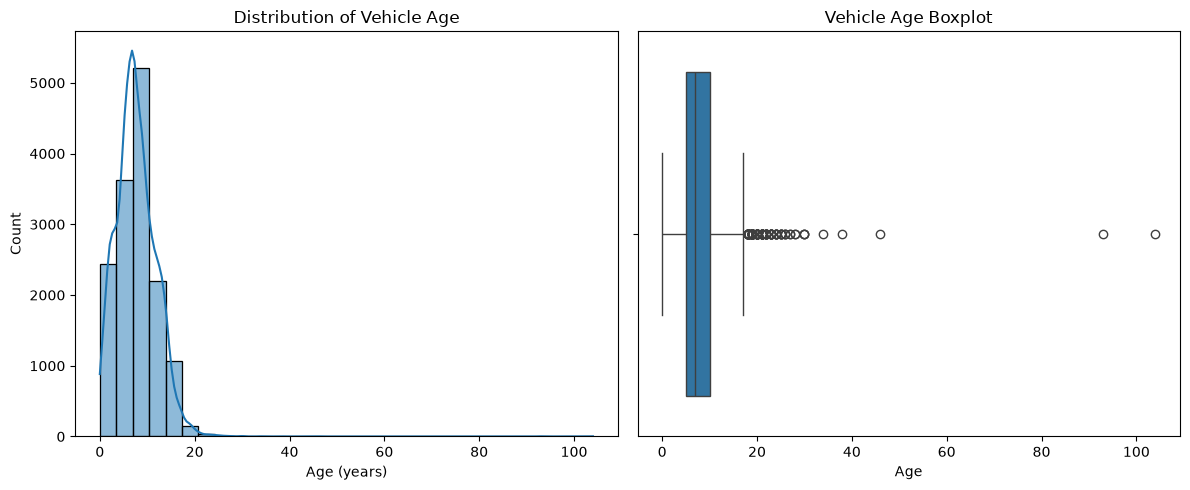

In [128]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['Age'], bins=30, kde=True, ax=ax[0])
ax[0].set_title('Distribution of Vehicle Age')
ax[0].set_xlabel('Age (years)')

sns.boxplot(x=df['Age'], ax=ax[1])
ax[1].set_title('Vehicle Age Boxplot')

plt.tight_layout()
plt.show()

THIS IS THE VISUALISATION OF THE FINAL VALUES ON THE AGE COLUMN

In [129]:
print(df['Year'].describe())

print("Skewness:", df['Year'].skew())
print("Missing values:", df['Year'].isna().sum())

count    14450.000000
mean      2016.290796
std          4.275158
min       1920.000000
25%       2014.000000
50%       2017.000000
75%       2019.000000
max       2024.000000
Name: Year, dtype: float64
Skewness: -1.8655182937932775
Missing values: 292


In [130]:
old_years = df[df['Year'] < 2000]

print(
    old_years[
        ['Brand', 'model', 'Year', 'Age', 'AdditionInfo']
    ].sort_values('Year').to_string()
)

               Brand         model    Year    Age                                                    AdditionInfo
22127  Maruti Suzuki         Swift  1920.0  104.0                   Maruti Suzuki Swift 1.2 LXI (O), 1920, Petrol
20842  Maruti Suzuki       Wagon-R  1931.0   93.0  Maruti Suzuki Wagon R 2010-2012 LXI BSIII, 1931, CNG & Hybrids
21040       Mahindra          Jeep  1978.0   46.0                             Mahindra Jeep Classic, 1978, Diesel
7404   Maruti Suzuki           NaN  1986.0   38.0                                              Maruti Suzuki SS80
1768          Toyota          Jeep  1990.0   34.0                                       Mahindra Jeep 1990 Diesel
2489   Mercedes-Benz       E-Class  1993.0   15.0           Mercedes-Benz E-Class 1993-2009 280 CDI, 2009, Diesel
508         Mahindra          Jeep  1994.0   30.0                    Mahindra Jeep Commander 750 DI, 1994, Diesel
6360   Maruti Suzuki           800  1994.0   30.0    Maruti Suzuki 800 1994 Petrol 70120

FROM THE STATS ON THE YEAR COLUMN I NOTICED THAT THE DISTRIBUTION WAS OFF, AFTER INVESTIGATING I NOTICED THAT MOST OF THE CARS LOOK RIGHT FOR THEIR AGE

In [131]:
year_from_info = (
    df['AdditionInfo']
    .str.extract(r'\b((?:19|20)\d{2})\b', expand=False)
)

year_from_info = pd.to_numeric(year_from_info, errors='coerce')

recoverable_years = df['Year'].isna() & year_from_info.notna()

print("Missing years:", df['Year'].isna().sum())
print("Rows with a year in AdditionInfo:", recoverable_years.sum())

print(
    df.loc[recoverable_years,
           ['Brand', 'model', 'Year', 'AdditionInfo']]
      .head(20)
      .to_string()
)

Missing years: 292
Rows with a year in AdditionInfo: 1
       Brand model  Year                                   AdditionInfo
8356  Toyota   Sx4   NaN  SX4 RC Valid till 2027 in Excellent Condition


THIS CODE I DENTIFIED YEARS THAT WERE STILL MISSING , AND ONES THAT HAD A YEAR IN ADDITIONALINFO COLUMN

In [132]:
missing_years = df[df['Year'].isna()]

print(
    missing_years[
        ['Brand', 'model', 'Age', 'AdditionInfo']
    ].head(30).to_string()
)

              Brand        model   Age                                                            AdditionInfo
13           Toyota            G  17.0         Top End Fully Loaded Automatic  Corolla with  Advanced Seq. CNG
46    Maruti Suzuki  Swift-Dzire   4.0                               Maruti Suzuki Swift Dzire Well Maintained
108        Mahindra       Bolero   9.0                                        Very good condition all paper ok
130         Hyundai            G   7.0                                                          Good condition
222   Maruti Suzuki         Alto   5.0            2019model Alto vxi top model  Well Maintained Doctor use car
231          Toyota         Alto   5.0                                                  Maruti Suzuki Alto 800
241             NaN  Swift-Dzire  11.0          Gadi me koi problem nahi hai cash or finance dono par ho jaegi
304          Toyota         Thar   7.0                           Top end Diesel automatic Mint thar , like new
3

A FURTHER INVESTIGATION SHOWED THE MISSING YEARS THE SPECIFIED COLUMNS, WHICH MAKES SENSE FOR ALL AS THEY ARE NOT ON THE ADDITIONAL INFO COLUMN

In [133]:
print(
    df.loc[df['Year'].isna(), 'Age']
      .value_counts(dropna=False)
      .sort_index()
)

Age
0.0      5
1.0     15
2.0     11
3.0     11
4.0     11
5.0     10
6.0     16
7.0     94
8.0     15
9.0     12
10.0    12
11.0    12
12.0    19
13.0     8
14.0    14
15.0     6
16.0     9
17.0     8
21.0     1
23.0     1
24.0     2
Name: count, dtype: int64


In [134]:
print("Missing years:", df['Year'].isna().sum())
print(df['Year'].describe())

Missing years: 292
count    14450.000000
mean      2016.290796
std          4.275158
min       1920.000000
25%       2014.000000
50%       2017.000000
75%       2019.000000
max       2024.000000
Name: Year, dtype: float64


In [135]:
print("Missing years:", df['Year'].isna().sum())

Missing years: 292


In [136]:
df['Year'] = df['Year'].fillna(df['Year'].median())

AFTER LOOKING AT WHETHER THERE ARE UNUSUAL PATTERNS ON THE YEAR COLUMN, WHICH THEY WERE NOT. I DECIDED TO IMPUTE WITH THE MISSING VALUES WITH THE MEDIAN OF THE YEAR COLUMN

In [137]:
print("Missing years:", df['Year'].isna().sum())
print(df['Year'].describe())

Missing years: 0
count    14742.000000
mean      2016.304843
std          4.233757
min       1920.000000
25%       2014.000000
50%       2017.000000
75%       2019.000000
max       2024.000000
Name: Year, dtype: float64


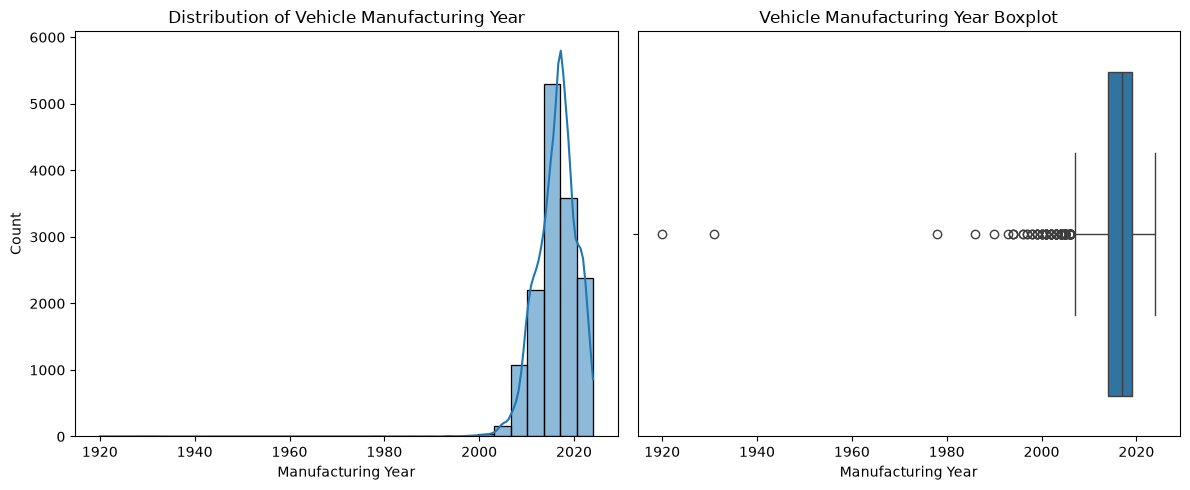

In [138]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['Year'], bins=30, kde=True, ax=ax[0])
ax[0].set_title('Distribution of Vehicle Manufacturing Year')
ax[0].set_xlabel('Manufacturing Year')

sns.boxplot(x=df['Year'], ax=ax[1])
ax[1].set_title('Vehicle Manufacturing Year Boxplot')
ax[1].set_xlabel('Manufacturing Year')

plt.tight_layout()
plt.show()

THIS IS THE VISUALISATION OF THE YEAR COLUMN 

In [139]:
df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,AskPrice_log,kmDriven_log,km_from_info
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0,12.180760,11.492733,NaN
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,12.834684,12.154785,NaN
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,12.128111,11.290911,NaN
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Diesel,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,13.244583,11.290911,NaN
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,13.437176,11.290911,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24570,Maruti Suzuki,Wagon-R,2022.0,2.0,31000.000000,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0,13.262127,10.341775,NaN
24571,BMW,X1,2017.0,7.0,45000.000000,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0,14.111905,10.714440,NaN
24572,Maruti Suzuki,New-gen Swift,2011.0,13.0,60000.000000,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0,11.982935,11.002117,NaN
24573,Tata,Zest,2019.0,5.0,62000.000000,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0,12.847929,11.034906,NaN


In [140]:
brand_counts = df['Brand'].value_counts(dropna=False)

print(brand_counts.head(20))
print("\nUnique brands:", df['Brand'].nunique())
print("Missing brands:", df['Brand'].isna().sum())

Brand
Maruti Suzuki    3797
Toyota           3476
Hyundai          1995
Honda            1016
Mahindra          571
Mercedes-Benz     495
Tata              487
Volkswagen        401
BMW               359
Ford              314
Renault           306
Audi              255
Skoda             216
Kia               176
NaN               132
Nissan            100
Chevrolet          99
MG                 83
Jeep               83
Land Rover         77
Name: count, dtype: int64

Unique brands: 40
Missing brands: 132


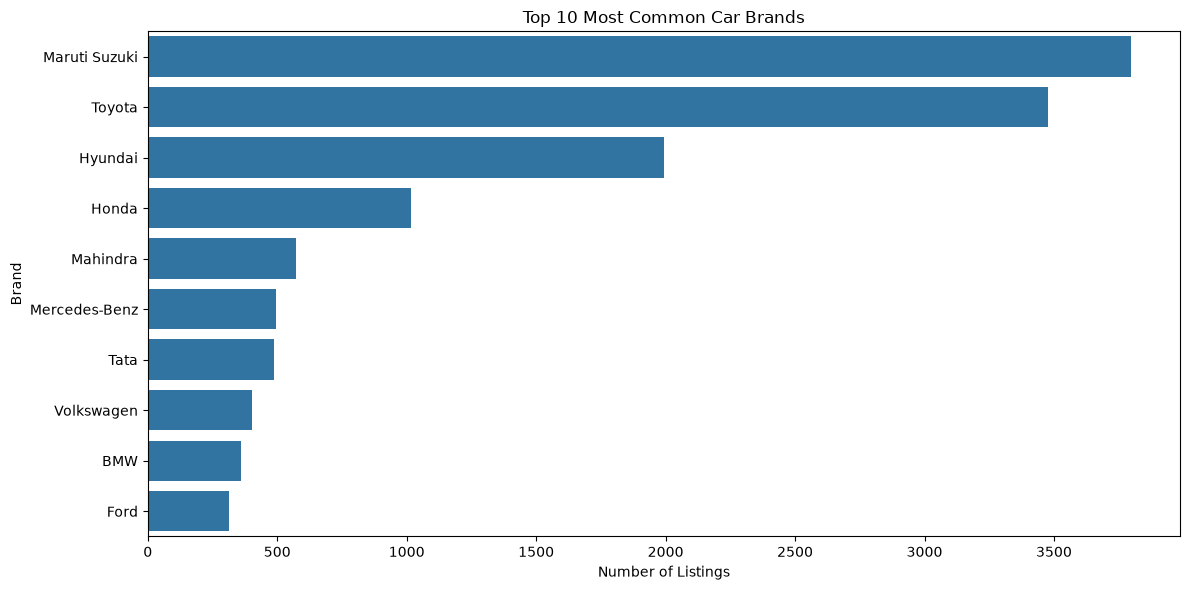

In [141]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='Brand',
    order=df['Brand'].value_counts().head(10).index
)

plt.title('Top 10 Most Common Car Brands')
plt.xlabel('Number of Listings')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

VISUALISATION OF THE 10 MOST LISTED CAR BRANDS 

In [142]:
df.loc[
    df['Brand'].isna(),
    ['model', 'Year', 'AdditionInfo']
].head(20)

,model,Year,AdditionInfo
99,Range Rover Evoque,2017.0,Vehicle is in very good condition
241,Swift-Dzire,2017.0,Gadi me koi problem nahi hai cash or finance d...
513,Alto-K10,2017.0,Good condition Alto k10 White colour (2017)
521,Alto,2015.0,"Alto k10 automatic car Less running, Good cond..."
547,Innova,2006.0,2006 innova G4 8 aeater
741,G,2015.0,Good condition
803,NaN,2019.0,"VITARA BREZZA ZDi AMT , SUNROOF WEBASTO,PVT LT..."
984,Brezza,2022.0,"Excellent condition,fully automatic."
1001,Alto-800,2016.0,Alto 800 for sale
1062,Seltos,2021.0,"KIA Seltos, Diesel, 35000 km driven in mint co..."



FROM THE OUTPUT I CAN SEE THAT MISSING BRANDS CAN POTENTIALLY BE RECOVERED

In [143]:
missing_brands = df.loc[
    df['Brand'].isna(),
    ['model', 'Year', 'AdditionInfo']
]

print(missing_brands.to_string())

                    model    Year                                                            AdditionInfo
99     Range Rover Evoque  2017.0                                       Vehicle is in very good condition
241           Swift-Dzire  2017.0          Gadi me koi problem nahi hai cash or finance dono par ho jaegi
513              Alto-K10  2017.0                             Good condition Alto k10 White colour (2017)
521                  Alto  2015.0                     Alto k10 automatic car Less running, Good condition
547                Innova  2006.0                                                 2006 innova G4 8 aeater
741                     G  2015.0                                                          Good condition
803                   NaN  2019.0          VITARA BREZZA ZDi AMT , SUNROOF WEBASTO,PVT LTD Company Owned.
984                Brezza  2022.0                                    Excellent condition,fully automatic.
1001             Alto-800  2016.0             

In [144]:
print("Rows with a known brand and model:",
      df.loc[df['Brand'].notna() & df['model'].notna()].shape[0])

print(df.loc[
    df['Brand'].notna() & df['model'].notna(),
    ['Brand', 'model']
].head(20).to_string(index=False))

Rows with a known brand and model: 14420
        Brand       model
        Honda        City
       Toyota           G
   Volkswagen       Vento
Maruti Suzuki       Swift
Maruti Suzuki      Baleno
          BMW          X3
       Toyota      Innova
          BMW    5 Series
Maruti Suzuki       Dzire
         Ford    Ecosport
Maruti Suzuki    Alto-K10
          Kia    Carnival
Maruti Suzuki Swift-Dzire
       Toyota           G
Mercedes-Benz   GLE COUPE
      Hyundai       Xcent
          Kia      Seltos
Maruti Suzuki      Ertiga
Maruti Suzuki      Ertiga
          BMW 3 Series GT


THIS LOOKS AT THE RELATIONSHIP BETWEEN BRAND AND MODEL 

In [145]:
model_brand_counts = (
    df.loc[df['Brand'].notna() & df['model'].notna()]
    .groupby('model')['Brand']
    .nunique()
)

print("Models linked to exactly one brand:",
      (model_brand_counts == 1).sum())

print("Models linked to multiple brands:",
      (model_brand_counts > 1).sum())

Models linked to exactly one brand: 144
Models linked to multiple brands: 258


THIS SHOWS US THE NUMBER OF MODEL LINKED TO ONE BRAND COMPARED TO BRAND LINKED TO MULTIPLE BRANDS

In [146]:
unique_model_brands = (
    df.loc[df['Brand'].notna() & df['model'].notna()]
    .groupby('model')['Brand']
    .first()
    .loc[lambda s: s.index.isin(
        model_brand_counts[model_brand_counts == 1].index
    )]
)

mask = df['Brand'].isna() & df['model'].isin(unique_model_brands.index)

print("Missing brands with a unique model match:", mask.sum())

print(
    df.loc[mask, ['model', 'Year', 'AdditionInfo']]
    .to_string()
)

Missing brands with a unique model match: 4
           model    Year                           AdditionInfo
547       Innova  2006.0                2006 innova G4 8 aeater
3317         GLS  2018.0        Mercedes Benz GLS GRAND EDITION
4025  Etios Liva  2011.0  Etios Liva 2011 Petrol showroom track
8586      Passat  2019.0                         Passat B8 2019


THIS CODE SHOWS US WHICH BRAND WE CAN RECOVER, IT IDENTIFIED 4 THAT WE WILL RECOVER

In [147]:
df.loc[mask, 'Brand'] = df.loc[mask, 'model'].map(unique_model_brands)

print("Missing brands remaining:", df['Brand'].isna().sum())

Missing brands remaining: 128


WE RECOVER THE BRANDS AND THE COUNT WENT DOWN BY EXACTLY 4

In [148]:
brand_names = [
    'Maruti Suzuki', 'Toyota', 'Hyundai', 'Honda',
    'Mahindra', 'Mercedes-Benz', 'Mercedes Benz',
    'Tata', 'Volkswagen', 'BMW', 'Ford', 'Renault',
    'Audi', 'Skoda', 'Kia', 'Nissan', 'Chevrolet',
    'MG', 'Jeep', 'Land Rover'
]

missing_brand_rows = df['Brand'].isna()

for brand in brand_names:
    matches = df.loc[
        missing_brand_rows
        & df['AdditionInfo'].str.contains(brand, case=False, na=False),
        ['model', 'Year', 'AdditionInfo']
    ]

    if not matches.empty:
        print(f"\n{brand}: {len(matches)} possible matches")
        print(matches.head(5).to_string())


Maruti Suzuki: 2 possible matches
     model    Year                          AdditionInfo
2711  Alto  2023.0  Maruti suzuki Alto800 VXI 2023 model
8154  Eeco  2018.0                    Maruti suzuki ecco

Honda: 1 possible matches
     model    Year                   AdditionInfo
3405   NaN  2017.0  HONDA CITY VX CVT(Petrol)2017

Mercedes Benz: 2 possible matches
        model    Year                                                            AdditionInfo
7158  E-Class  2012.0  Mercedes Benz E Class 2012 KL Diesel 73000 Km W212 new batt tyre brake
9213  M-Class  2013.0                       Mercedes Benz ML 350 Top Model Vehicle Not ML 250

BMW: 2 possible matches
     model    Year                       AdditionInfo
1078   NaN  2017.0  bmw 3 series cleanest in the town
2595   NaN  2016.0                       bmw 3 series

Kia: 1 possible matches
       model    Year                                           AdditionInfo
1062  Seltos  2021.0  KIA Seltos, Diesel, 35000 km driven in m

This only identifies possible matches; it doesn't change your data
THIS CODE IDENTIFIES POSSIBLE MATCHES ON THE ADDITIONAL INFO COLUMN FROM THE SPECIFIED LIST

In [149]:
brand_recovery = {
    2711: 'Maruti Suzuki',
    8154: 'Maruti Suzuki',
    3405: 'Honda',
    7158: 'Mercedes-Benz',
    9213: 'Mercedes-Benz',
    1078: 'BMW',
    2595: 'BMW',
    1062: 'Kia',
    7049: 'MG'
}

for idx, brand in brand_recovery.items():
    if pd.isna(df.loc[idx, 'Brand']):
        df.loc[idx, 'Brand'] = brand

print("Missing brands remaining:", df['Brand'].isna().sum())

Missing brands remaining: 119


FROM THE IDENTIFIED MATCHES I WAS ABLE TO RECOVER QUITE A FEW MORE BRANDS

In [150]:
brand_names = [
    'Maruti Suzuki', 'Toyota', 'Hyundai', 'Honda',
    'Mahindra', 'Mercedes-Benz', 'Mercedes Benz',
    'Tata', 'Volkswagen', 'BMW', 'Ford', 'Renault',
    'Audi', 'Skoda', 'Kia', 'Nissan', 'Chevrolet',
    'MG', 'Jeep', 'Land Rover'
]

missing_brand_rows = df['Brand'].isna()

for brand in brand_names:
    matches = df.loc[
        missing_brand_rows
        & df['AdditionInfo'].str.contains(brand, case=False, na=False),
        ['model', 'Year', 'AdditionInfo']
    ]

    if not matches.empty:
        print(f"\n{brand}: {len(matches)} possible matches")
        print(matches.to_string())


Chevrolet: 1 possible matches
     model    Year                                    AdditionInfo
7688     G  2011.0  CHEVROLET SPARK 2011 WITH RTO APPROVED CNG KIT


In [151]:
df.loc[7688, 'Brand'] = 'Chevrolet'

print("Missing brands remaining:", df['Brand'].isna().sum())

Missing brands remaining: 118


In [152]:
matches = df.loc[
    df['Brand'].isna()
    & df['AdditionInfo'].str.contains('Toyota', case=False, na=False),
    ['model', 'Year', 'AdditionInfo']
]

print(f"Toyota mentions: {len(matches)}")
print(matches.to_string())

Toyota mentions: 0
Empty DataFrame
Columns: [model, Year, AdditionInfo]
Index: []


In [153]:
matches = df.loc[
    df['Brand'].isna()
    & df['AdditionInfo'].str.contains('Hyundai', case=False, na=False),
    ['model', 'Year', 'AdditionInfo']
]

print(f"Hyundai mentions: {len(matches)}")
print(matches.to_string())

Hyundai mentions: 0
Empty DataFrame
Columns: [model, Year, AdditionInfo]
Index: []


AFTER FINDING THE MATCHES FOR THE GROUPED BRANDS, I TRIED TO FIND MORE BY LOOKING AT INDIVIDUAL BRAND BUT I STILL HAD NO LUCK

In [154]:
print(
    df.loc[
        df['Brand'].isna(),
        ['model', 'Year', 'AdditionInfo']
    ].to_string()
)

                    model    Year                                                            AdditionInfo
99     Range Rover Evoque  2017.0                                       Vehicle is in very good condition
241           Swift-Dzire  2017.0          Gadi me koi problem nahi hai cash or finance dono par ho jaegi
513              Alto-K10  2017.0                             Good condition Alto k10 White colour (2017)
521                  Alto  2015.0                     Alto k10 automatic car Less running, Good condition
741                     G  2015.0                                                          Good condition
803                   NaN  2019.0          VITARA BREZZA ZDi AMT , SUNROOF WEBASTO,PVT LTD Company Owned.
984                Brezza  2022.0                                    Excellent condition,fully automatic.
1001             Alto-800  2016.0                                                       Alto 800 for sale
1077                  NaN  2018.0             

THE OUTPUT ABOVE REVEALED MORE BRANDS WHICH WE MAYBE BE ABLE TO EXTRACT FROM THE ADDITIONAL INFO

In [155]:
models_to_check = [
    'Range Rover Evoque', 'Swift-Dzire', 'Alto-K10',
    'Alto', 'Brezza', 'Alto-800', 'Nexon',
    'i20 Active', 'Polo', 'Verna', 'Sumo Gold',
    'Indica Vista', 'Eeco', 'Wagon-R-1-0', 'Indigo Ecs'
]

print(
    df.loc[
        df['model'].isin(models_to_check) & df['Brand'].notna(),
        ['Brand', 'model']
    ]
    .drop_duplicates()
    .sort_values(['model', 'Brand'])
    .to_string(index=False)
)

        Brand              model
Maruti Suzuki               Alto
       Toyota               Alto
Maruti Suzuki           Alto-800
       Toyota           Alto-800
Maruti Suzuki           Alto-K10
       Toyota           Alto-K10
Maruti Suzuki             Brezza
       Toyota             Brezza
Maruti Suzuki               Eeco
       Toyota               Eeco
         Tata       Indica Vista
       Toyota       Indica Vista
         Tata         Indigo Ecs
       Toyota         Indigo Ecs
         Tata              Nexon
       Toyota              Nexon
       Toyota               Polo
   Volkswagen               Polo
   Land Rover Range Rover Evoque
       Toyota Range Rover Evoque
Maruti Suzuki        Swift-Dzire
       Toyota        Swift-Dzire
      Hyundai              Verna
       Toyota              Verna
Maruti Suzuki        Wagon-R-1-0
       Toyota        Wagon-R-1-0
      Hyundai         i20 Active
       Toyota         i20 Active


THE OUTPUT REVEALED THAT SOME MODELS WERE LINKED TO THE SAME CAR BRAND 

In [156]:
print(
    df.loc[
        df['Brand'].isna()
        & (
            df['model'].isna()
            | df['model'].eq('G')
        ),
        ['model', 'Year', 'AdditionInfo']
    ].to_string()
)

     model    Year                                                            AdditionInfo
741      G  2015.0                                                          Good condition
803    NaN  2019.0          VITARA BREZZA ZDi AMT , SUNROOF WEBASTO,PVT LTD Company Owned.
1077   NaN  2018.0                                                           New condition
1125     G  2017.0                                                          GOOD CONDATION
1358   NaN  2017.0                                         All parts available for zen vxi
1444   NaN  2013.0                                           Fourtuner car 2013 vip number
1909   NaN  2017.0                                             Urgent sale new car parches
2316   NaN  2022.0                                                     very nice condition
2381   NaN  2017.0                                                    Sunroof android auto
2746   NaN  2022.0                                    Excellent condition,fully automatic.

In [157]:
candidate_indices = [803, 1358, 1444, 3864, 5648, 5842, 6257, 9102]

print(
    df.loc[
        candidate_indices,
        ['Brand', 'model', 'Year', 'AdditionInfo']
    ].to_string()
)

     Brand model    Year                                                    AdditionInfo
803    NaN   NaN  2019.0  VITARA BREZZA ZDi AMT , SUNROOF WEBASTO,PVT LTD Company Owned.
1358   NaN   NaN  2017.0                                 All parts available for zen vxi
1444   NaN   NaN  2013.0                                   Fourtuner car 2013 vip number
3864   NaN   NaN  2017.0                                   Dezier in very good condition
5648   NaN   NaN  2017.0                                           Fully loaded city zxi
5842   NaN   NaN  2022.0                 Zeta Automatic, Under 5 years Extended Warranty
6257   NaN     G  2017.0          T-Permit Dec-2017 Maruti Wagon-R LXI-CNG Car for Sell.
9102   NaN   NaN  2021.0                   Top end Diesel automatic Mint thar , like new


BY FURTHER INVESTIGATING ON THE SPECIFIED CANDIDATE ROWS I CAN BE ABLE TO RECOVER A FEW MORE ROWS

In [158]:
brand_recovery = {
    803: 'Maruti Suzuki',
    1358: 'Maruti Suzuki',
    1444: 'Toyota',
    3864: 'Maruti Suzuki',
    5648: 'Honda',
    6257: 'Maruti Suzuki',
    9102: 'Mahindra'
}

for idx, brand in brand_recovery.items():
    if pd.isna(df.loc[idx, 'Brand']):
        df.loc[idx, 'Brand'] = brand

print("Missing brands remaining:", df['Brand'].isna().sum())

Missing brands remaining: 111


I RECOVERED 7 MORE BRANDS AND THERE ARE 111 MORE MISSING

In [159]:
missing = df.loc[
    df['Brand'].isna(),
    ['model', 'Year', 'AdditionInfo']
]

print(missing.iloc[30:60].to_string())

            model    Year                                                            AdditionInfo
4466            G  2017.0                                               Good condition ac working
4823       Baleno  2017.0                                         Maruthi suzuki baleno automatic
4879         Ritz  2017.0                                          Ritz vdi abs in good condition
4928     Alto K10  2011.0                                                     Alto K10 zen estilo
5021       XUV300  2017.0                                      XUV300 W6 Diesel Automatic 14555km
5040            G  2017.0                                             Gadi new condition mein hai
5108       Accent  2011.0      2011 November ki hai Key mene automatically all sisa automatically
5156          NaN  2024.0                                             Koi v gaddi pe loan mile ga
5245      XUV 300  2022.0                                        Xuv300 Diesel Automatic 14555 km
5309         Ritz  2

THIS SHOWS US THAT WE CAN IDENTIFY SOME OF THE MISSING BRAND SOLELY FROM THEIR DESCRIPTION

In [160]:
candidate_indices = [
    4823, 4879, 5021, 5245, 5309,
    5388, 5602, 5617, 5749, 5762,
    5910, 5976, 6116, 6188, 6211
]

print(
    df.loc[
        candidate_indices,
        ['Brand', 'model', 'Year', 'AdditionInfo']
    ].to_string()
)

     Brand        model    Year                                     AdditionInfo
4823   NaN       Baleno  2017.0                  Maruthi suzuki baleno automatic
4879   NaN         Ritz  2017.0                   Ritz vdi abs in good condition
5021   NaN       XUV300  2017.0               XUV300 W6 Diesel Automatic 14555km
5245   NaN      XUV 300  2022.0                 Xuv300 Diesel Automatic 14555 km
5309   NaN         Ritz  2016.0             Ritz zxi 2016 Re-registered for sale
5388   NaN          i10  2010.0                  i10 in mint condition for sale.
5602   NaN      Wagon-R  2016.0                          Wagone r Automatic 2016
5617   NaN    Grand i10  2014.0          CNG plus petrol good Mileage model 2014
5749   NaN         KWID  2018.0                                    RXT KWID 2018
5762   NaN         KWID  2017.0                 CNG car with GPS  good condition
5910   NaN         Eeco  2017.0                 New baterry new Tyrs ok kandison
5976   NaN    Sail U-VA  201

In [161]:
brand_recovery = {
    4823: 'Maruti Suzuki',
    4879: 'Maruti Suzuki',
    5021: 'Mahindra',
    5245: 'Mahindra',
    5309: 'Maruti Suzuki',
    5388: 'Hyundai',
    5602: 'Maruti Suzuki',
    5617: 'Hyundai',
    5749: 'Renault',
    5762: 'Renault',
    5910: 'Maruti Suzuki',
    5976: 'Chevrolet',
    6116: 'Maruti Suzuki',
    6188: 'Maruti Suzuki',
    6211: 'Maruti Suzuki'
}

for idx, brand in brand_recovery.items():
    if pd.isna(df.loc[idx, 'Brand']):
        df.loc[idx, 'Brand'] = brand

print("Missing brands remaining:", df['Brand'].isna().sum())

Missing brands remaining: 96


FROM THE CODE ABOVE I DENTIFIED THE CANDIDATE ROWS AND FILLED THEM WITH THE DESCRIPTIONS THAT WERE AVAILBLE

In [162]:
df.loc[
    df['Brand'].isna(),
    ['model', 'Year', 'AdditionInfo']
].to_string()

'                    model    Year                                                            AdditionInfo\n99     Range Rover Evoque  2017.0                                       Vehicle is in very good condition\n241           Swift-Dzire  2017.0          Gadi me koi problem nahi hai cash or finance dono par ho jaegi\n513              Alto-K10  2017.0                             Good condition Alto k10 White colour (2017)\n521                  Alto  2015.0                     Alto k10 automatic car Less running, Good condition\n741                     G  2015.0                                                          Good condition\n984                Brezza  2022.0                                    Excellent condition,fully automatic.\n1001             Alto-800  2016.0                                                       Alto 800 for sale\n1077                  NaN  2018.0                                                           New condition\n1125                    G  2017.0   

In [163]:
model_to_brand = {
    'Range Rover Evoque': 'Land Rover',
    'Swift-Dzire': 'Maruti Suzuki',
    'Alto-K10': 'Maruti Suzuki',
    'Alto K10': 'Maruti Suzuki',
    'Alto': 'Maruti Suzuki',
    'Alto-800': 'Maruti Suzuki',
    'Brezza': 'Maruti Suzuki',
    'Nexon': 'Tata',
    'i20 Active': 'Hyundai',
    'i20': 'Hyundai',
    'Polo': 'Volkswagen',
    'Verna': 'Hyundai',
    'Sumo Gold': 'Tata',
    'Indica Vista': 'Tata',
    'Marazzo': 'Mahindra',
    'Santro Xing': 'Hyundai',
    'Santro': 'Hyundai',
    'Vento': 'Volkswagen',
    'Wagon-R': 'Maruti Suzuki',
    'Wagon-R-1-0': 'Maruti Suzuki',
    'TUV': 'Mahindra',
    'Omni': 'Maruti Suzuki',
    'Accent': 'Hyundai',
    'Civic': 'Honda',
    'City Hybrid eHEV': 'Honda',
    'Xylo': 'Mahindra',
    'Eon': 'Hyundai',
    'Superb': 'Skoda',
    'KWID': 'Renault',
    'Ertiga': 'Maruti Suzuki',
    'Ciaz': 'Maruti Suzuki',
    'Eeco': 'Maruti Suzuki',
    'Endeavour': 'Ford',
    'Baleno': 'Maruti Suzuki',
    'Indigo Ecs': 'Tata',
    'Hyryder': 'Toyota'
}

for idx in df.index[df['Brand'].isna()]:
    model = df.loc[idx, 'model']

    if pd.notna(model) and model in model_to_brand:
        df.loc[idx, 'Brand'] = model_to_brand[model]

description_recovery = {
    7867: 'Maruti Suzuki',  
    8849: 'Maruti Suzuki',  
    8879: 'Maruti Suzuki',  
    7697: 'Toyota'          
}

for idx, brand in description_recovery.items():
    if idx in df.index and pd.isna(df.loc[idx, 'Brand']):
        df.loc[idx, 'Brand'] = brand

print("Missing brands remaining:", df['Brand'].isna().sum())
print("Total rows preserved:", len(df))

Missing brands remaining: 36
Total rows preserved: 14742


I MAPPED THE REMAINING BRAND USING THEIR MATCHING BRANDS 

In [164]:
df.loc[
    df['Brand'].isna(),
    ['model', 'Year', 'AdditionInfo']
]

,model,Year,AdditionInfo
741,G,2015.0,Good condition
1077,NaN,2018.0,New condition
1125,G,2017.0,GOOD CONDATION
1909,NaN,2017.0,Urgent sale new car parches
2316,NaN,2022.0,very nice condition
2381,NaN,2017.0,Sunroof android auto
2746,NaN,2022.0,"Excellent condition,fully automatic."
4259,Swift,2017.0,Brand new condition
4466,G,2017.0,Good condition ac working
5040,G,2017.0,Gadi new condition mein hai


In [165]:
for idx in [4259, 7170]:
    if pd.isna(df.loc[idx, 'Brand']):
        df.loc[idx, 'Brand'] = 'Maruti Suzuki'

print("Missing brands remaining:", df['Brand'].isna().sum())
print("Total rows preserved:", len(df))

Missing brands remaining: 34
Total rows preserved: 14742


I HAVE IDENTIFIED ALL BRANDS THAT WERE MISSING AND AVAILABLE ON THE ADDITIONAL INFO COLUMN

In [166]:
print("Missing models:", df['model'].isna().sum())

df.loc[
    df['model'].isna(),
    ['Brand', 'Year', 'AdditionInfo']
].head(20)

Missing models: 225


,Brand,Year,AdditionInfo
53,Toyota,2016.0,7 Seater Honda BR-V with 20+Avg.
139,Toyota,2016.0,XUV 500W10 2015/2016
167,Mercedes-Benz,2012.0,Mercedes Benz E Class 2012 KL Diesel 73000 Km ...
201,Toyota,2010.0,"Doctors Private RITZ with AC,Power Window,Powe..."
284,Land Rover,2016.0,"Land Rover Range Evoque 2015-2016 HSE, 2016, D..."
331,Toyota,2016.0,"Aston Martin Vanquish 6.0 V12, 2016, Petrol"
478,Maruti Suzuki,2017.0,Single owner
658,Tata,2009.0,Tata Indigo CS 2009
668,Maruti Suzuki,2017.0,Selling Urgent
729,Maruti Suzuki,2024.0,Red color 2024 model brezza lxi


In [167]:
model_brand_map = {
    'Honda BR-V': 'Honda',
    'XUV 500': 'Mahindra',
    'E Class': 'Mercedes-Benz',
    'Range Rover Evoque': 'Land Rover',
    'Aston Martin Vanquish': 'Aston Martin',
    'Ritz': 'Maruti Suzuki',
    'Indigo CS': 'Tata',
    'Brezza': 'Maruti Suzuki',
    'Tata Punch': 'Tata',
    'Verna': 'Hyundai',
    'Mitsubishi Cedia': 'Mitsubishi',
    'D-Max': 'Isuzu',
    'Vitara Brezza': 'Maruti Suzuki',
    'Zen': 'Maruti Suzuki',
    'City': 'Honda',
    'LX 500d': 'Lexus'
}

# Match model names in descriptions only when the brand is consistent
recovered = 0
conflicts = []

for idx in df.index[df['model'].isna()]:
    info = df.at[idx, 'AdditionInfo']

    if pd.isna(info):
        continue

    for model_name, expected_brand in model_brand_map.items():
        if re.search(re.escape(model_name), str(info), flags=re.IGNORECASE):
            current_brand = df.at[idx, 'Brand']

            if pd.isna(current_brand) or current_brand == expected_brand:
                df.at[idx, 'model'] = model_name
                recovered += 1
            else:
                conflicts.append((idx, current_brand, model_name, expected_brand))

            break

print("Models recovered:", recovered)
print("Missing models remaining:", df['model'].isna().sum())
print("Brand conflicts to review:", len(conflicts))
print("Total rows preserved:", len(df))

Models recovered: 16
Missing models remaining: 209
Brand conflicts to review: 11
Total rows preserved: 14742


I MAPPED THE MODELS THAT WERE MISSING AND RETURNED THE TOTAL RECOVERED, MISSING MODELS, CONFLICTS AND ROWS PRESERVED

In [168]:
for conflict in conflicts:
    print(conflict)

(53, 'Toyota', 'Honda BR-V', 'Honda')
(139, 'Toyota', 'XUV 500', 'Mahindra')
(201, 'Toyota', 'Ritz', 'Maruti Suzuki')
(331, 'Toyota', 'Aston Martin Vanquish', 'Aston Martin')
(736, 'Toyota', 'Tata Punch', 'Tata')
(5909, 'Toyota', 'Honda BR-V', 'Honda')
(7291, 'Toyota', 'Indigo CS', 'Tata')
(7400, 'Toyota', 'Tata Punch', 'Tata')
(7832, 'Toyota', 'Honda BR-V', 'Honda')
(8327, 'Maruti Suzuki', 'City', 'Honda')
(8989, 'Toyota', 'City', 'Honda')


THIS SHOWS ME THE OUTPUT OF THE CONFLICTING MODELS

In [169]:
conflict_indices = [c[0] for c in conflicts]

df.loc[
    conflict_indices,
    ['Brand', 'model', 'Year', 'AdditionInfo']
]

,Brand,model,Year,AdditionInfo
53,Toyota,NaN,2016.0,7 Seater Honda BR-V with 20+Avg.
139,Toyota,NaN,2016.0,XUV 500W10 2015/2016
201,Toyota,NaN,2010.0,"Doctors Private RITZ with AC,Power Window,Powe..."
331,Toyota,NaN,2016.0,"Aston Martin Vanquish 6.0 V12, 2016, Petrol"
736,Toyota,NaN,2022.0,"Tata Punch, 2022, Petrol"
5909,Toyota,NaN,2019.0,Honda BR-V 2019 Petrol 122000 Km Driven
7291,Toyota,NaN,2010.0,Tata Indigo CS 2010 Diesel 164000 Km Driven
7400,Toyota,NaN,2017.0,Tata punch camo accomplished dazzle automatic ...
7832,Toyota,NaN,2016.0,"Honda BR-V Style Edition V CVT, 2016, Petrol"
8327,Maruti Suzuki,NaN,2013.0,Anil Pandit from merta city wegonr vxi 2013 mo...


THIS SHOWS CARS THAT WERE MISIDENTIFIED AND MUST BE CORRECTED 

In [170]:
corrections = {
    53:   ('Honda', 'BR-V'),
    139:  ('Mahindra', 'XUV 500'),
    201:  ('Maruti Suzuki', 'Ritz'),
    331:  ('Aston Martin', 'Vanquish'),
    736:  ('Tata', 'Punch'),
    5909: ('Honda', 'BR-V'),
    7291: ('Tata', 'Indigo CS'),
    7400: ('Tata', 'Punch'),
    7832: ('Honda', 'BR-V'),
    8327: ('Maruti Suzuki', 'Wagon-R'),
    8989: ('Honda', 'City')
}

for idx, (brand, model) in corrections.items():
    df.loc[idx, 'Brand'] = brand
    df.loc[idx, 'model'] = model

print("Missing models remaining:", df['model'].isna().sum())
print("Missing brands remaining:", df['Brand'].isna().sum())
print("Total rows preserved:", len(df))

Missing models remaining: 198
Missing brands remaining: 34
Total rows preserved: 14742


THIS CODE CORRECTS THE MODEL THAT WERE MISIDENTIFIED

In [171]:
missing_models = df[df['model'].isna()]

print(
    missing_models[['Brand', 'AdditionInfo']]
    .to_string(index=True)
)

              Brand                                                            AdditionInfo
284      Land Rover                     Land Rover Range Evoque 2015-2016 HSE, 2016, Diesel
478   Maruti Suzuki                                                            Single owner
668   Maruti Suzuki                                                          Selling Urgent
761          Toyota                                                        Mitsubishi cidea
939   Maruti Suzuki                                                   Sale for urgent money
1077            NaN                                                           New condition
1078            BMW                                       bmw 3 series cleanest in the town
1189  Maruti Suzuki                               Single driver, low mileage, excellent car
1237         Toyota                             2022-23 ŠKODA KUSHAQ 1.0 AMBITION AUTOMATIC
1302     Land Rover                       Land Rover Range Evoque HSE Dynamic, 2

In [172]:
model_patterns = {
    'Range Evoque': 'Range Rover Evoque',
    'Range Rover Evoque': 'Range Rover Evoque',
    'Range Sport': 'Range Rover Sport',
    'Range Rover Sport': 'Range Rover Sport',
    'Range Velar': 'Range Rover Velar',
    'BMW 3 series': '3 Series',
    'BMW 520d': '520d',
    'BMW 525D': '525d',
    'BMW 520d': '520d',
    'ŠKODA KUSHAQ': 'Kushaq',
    'Mitsubishi cidea': 'Cedia',
    'TATA NANO': 'Nano',
    'Fourtuner': 'Fortuner',
    'Suzuki ertiga': 'Ertiga',
    'FORD ENDEAVOUR': 'Endeavour',
    'Lexus LX 450d': 'LX 450d',
    'Lexus LX 500d': 'LX 500d',
    'Mercedes-Benz S400L': 'S400L',
    '220 NM Turbo powered Astor': 'Astor',
    'Tata safari': 'Safari',
    'Audi a4': 'A4',
    'I sell eon car': 'Eon'
}

recovered = 0

for idx in df.index[df['model'].isna()]:
    info = df.at[idx, 'AdditionInfo']

    if pd.isna(info):
        continue

    for pattern, model_name in model_patterns.items():
        if re.search(re.escape(pattern), str(info), flags=re.IGNORECASE):
            df.at[idx, 'model'] = model_name
            recovered += 1
            break

print("Models recovered in this pass:", recovered)
print("Missing models remaining:", df['model'].isna().sum())
print("Total rows preserved:", len(df))

Models recovered in this pass: 41
Missing models remaining: 157
Total rows preserved: 14742


HERE I FURTHER MAP THE MISSING VALUES THAT WERE IDENTIFIED BY THE CODE

In [173]:
df.loc[
    df['model'].isna(),
    ['Brand', 'Year', 'AdditionInfo']
].head(60).to_string()

'              Brand    Year                                                          AdditionInfo\n478   Maruti Suzuki  2017.0                                                          Single owner\n668   Maruti Suzuki  2017.0                                                        Selling Urgent\n939   Maruti Suzuki  2017.0                                                 Sale for urgent money\n1077            NaN  2018.0                                                         New condition\n1189  Maruti Suzuki  2017.0                             Single driver, low mileage, excellent car\n1592  Maruti Suzuki  2017.0                                                   Value for money car\n1646         Toyota  2015.0             A well maintained and single handed driven since begining\n1652  Maruti Suzuki  2017.0                                                  Very good condistion\n1675  Maruti Suzuki  2020.0                                     Very good condition top end model\n1682  Mar

In [174]:
import re
import pandas as pd

model_patterns = {
    r'\bS\s*P?resso\b': 'S-Presso',
    r'\bSonet\b': 'Sonet',
    r'\bRapid\b': 'Rapid',
    r'\bIndigo\s*ECS\b': 'Indigo Ecs',
    r'\bChevrolet\s+Beat\b|\bCheverlet\s+Beat\b': 'Beat',
    r'\bVolvo\s+S\s*80\b|\bS80\b': 'S80',
    r'\bWagon\s*R\b|\bWagonR\b': 'Wagon-R',
    r'\bMitsubishi\s+Lancer\b': 'Lancer',
    r'\bTata\s+Nexon\b|\bNexon\b': 'Nexon',
    r'\bHyundai\s+Xcent\b|\bXcent\b': 'Xcent',
    r'\bBMW\s+X\s*3\b|\bX\s*3\b': 'X3',
    r'\bI\s*20\s+Magna\b|\bI\s*20\s+Sportz\b|\bI\s*20\b': 'i20',
    r'\bPolo\s+Highline\b|\bPolo\b': 'Polo',
    r'\bDzire\b|\bDezier\b': 'Swift-Dzire',
    r'\bRange\s+SE\b': 'Range Rover',
    r'\bForce\s+One\b': 'Force One',
    r'\be2o\b': 'e2o',
    r'\bSLK\s*350\b|\bSLK-Class\b': 'SLK-Class',
    r'\bCelerio\b': 'Celerio'
}

recovered = []

for idx in df.index[df['model'].isna()]:
    info = df.at[idx, 'AdditionInfo']

    if pd.isna(info):
        continue

    for pattern, model_name in model_patterns.items():
        if re.search(pattern, str(info), flags=re.IGNORECASE):
            df.at[idx, 'model'] = model_name
            recovered.append(idx)
            break

print("Models recovered in this pass:", len(recovered))
print("Missing models remaining:", df['model'].isna().sum())
print("Total rows preserved:", len(df))

Models recovered in this pass: 27
Missing models remaining: 130
Total rows preserved: 14742


I IDENTIFIED A FURTHER 60 MISSING COLUMNS AND UPDATED THEM WITH THE INFORMATION FROM THE ADDITIONAL COLUMN

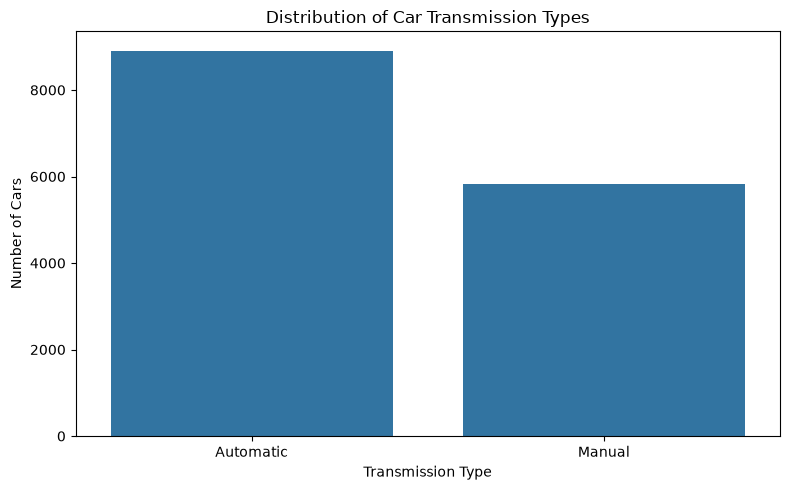

In [175]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Transmission')

plt.title('Distribution of Car Transmission Types')
plt.xlabel('Transmission Type')
plt.ylabel('Number of Cars')

plt.tight_layout()
plt.show()

THIS VISUALISATION SHOWS THE CAR TRANSMISSION THAT IS PRESENT THE MOST

C:\Users\Leboh\AppData\Local\Temp\ipykernel_3880\514823920.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])


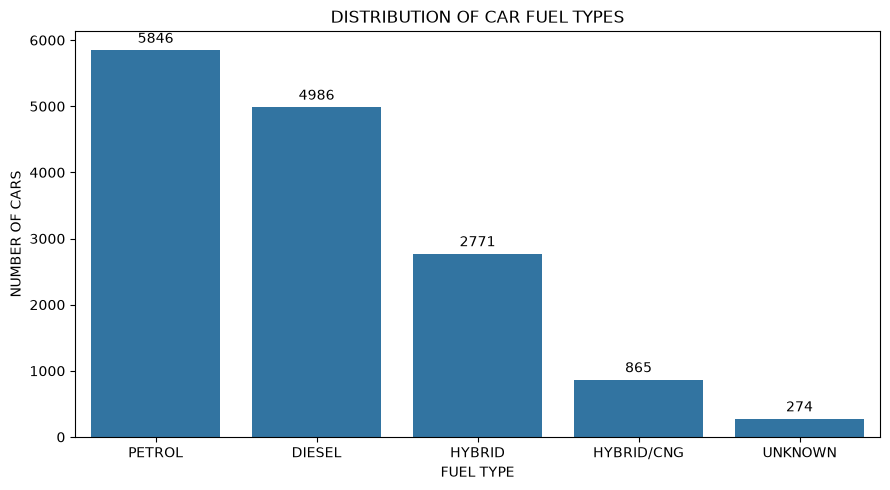

In [176]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x='FuelType',
    order=df['FuelType'].value_counts().index
)

plt.title('DISTRIBUTION OF CAR FUEL TYPES')
plt.xlabel('FUEL TYPE')
plt.ylabel('NUMBER OF CARS')

# CAPITALISE CATEGORY LABELS
ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])

# ADD COUNTS ABOVE THE BARS
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

THIS SHOWS THE DISTRIBUTION OF THE FUEL TYPES, WHICH ALSO HIGHLIGHTS THAT THERE IS THE UNKNOWN VALUES AS WELL

In [177]:
fuel_counts = df['FuelType'].value_counts()
fuel_percentages = df['FuelType'].value_counts(normalize=True) * 100

fuel_summary = pd.DataFrame({
    'Count': fuel_counts,
    'Percentage': fuel_percentages.round(2)
})

print(fuel_summary)

            Count  Percentage
FuelType                     
Petrol       5846       39.66
Diesel       4986       33.82
hybrid       2771       18.80
Hybrid/CNG    865        5.87
Unknown       274        1.86


THE UNIVARIATE ANALYSIS OF FUELTYPE SHOWS THAT PETROL IS THE MOST COMMON CATEGORY (39.66%), FOLLOWED BY DIESEL (33.82%) AND HYBRID (18.80%). HYBRID/CNG ACCOUNTS FOR 5.87% OF THE LISTINGS, WHILE UNKNOWN REPRESENTS ONLY 1.86%. OVERALL, PETROL AND DIESEL DOMINATE THE DATASET, TOGETHER ACCOUNTING FOR 73.48% OF ALL VEHICLES. THE UNKNOWN CATEGORY REPRESENTS A SMALL PROPORTION OF LISTINGS WITH UNIDENTIFIED FUEL TYPES.

THIS IS THE SECTION OF CODE WHERE I DO BIVARIATE ANALYSIS

In [178]:
df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,AskPrice_log,kmDriven_log,km_from_info
0,Honda,City,2001.0,23.0,98000.000000,Automatic,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0,12.180760,11.492733,NaN
1,Toyota,G,2009.0,15.0,190000.000000,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,12.834684,12.154785,NaN
2,Volkswagen,Vento,2010.0,14.0,80089.393405,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,12.128111,11.290911,NaN
3,Maruti Suzuki,Swift,2017.0,7.0,80089.393405,Manual,second,Diesel,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,13.244583,11.290911,NaN
4,Maruti Suzuki,Baleno,2019.0,5.0,80089.393405,Automatic,NaN,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,13.437176,11.290911,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24570,Maruti Suzuki,Wagon-R,2022.0,2.0,31000.000000,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0,13.262127,10.341775,NaN
24571,BMW,X1,2017.0,7.0,45000.000000,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0,14.111905,10.714440,NaN
24572,Maruti Suzuki,New-gen Swift,2011.0,13.0,60000.000000,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0,11.982935,11.002117,NaN
24573,Tata,Zest,2019.0,5.0,62000.000000,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0,12.847929,11.034906,NaN


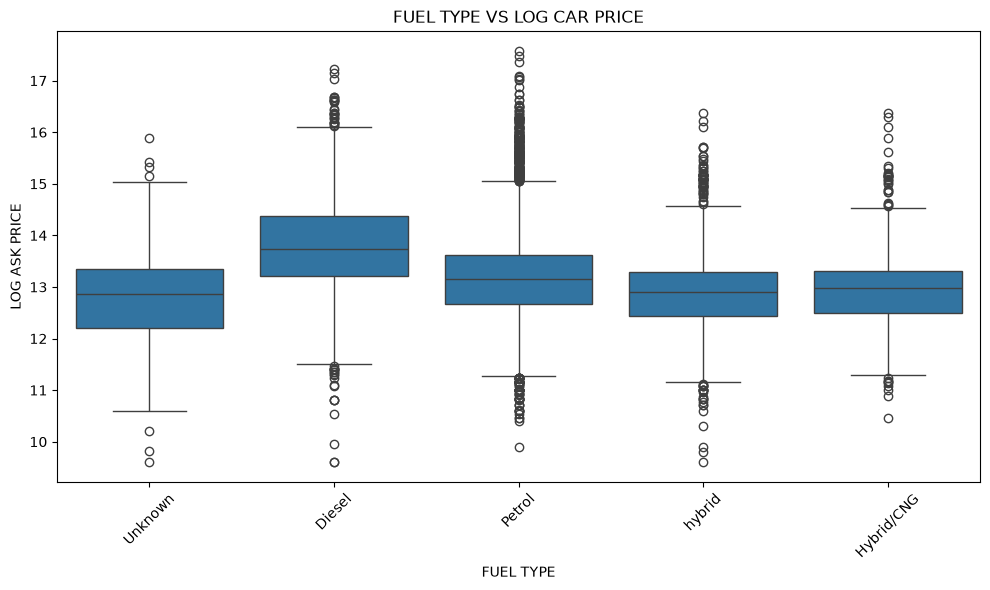

In [179]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='FuelType',
    y='AskPrice_log'
)

plt.title('FUEL TYPE VS LOG CAR PRICE')
plt.xlabel('FUEL TYPE')
plt.ylabel('LOG ASK PRICE')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

DIESEL VEHICLES HAVE THE HIGHEST MEDIAN LOG ASK PRICE, FOLLOWED BY PETROL. PETROL HAS MANY HIGH-PRICE OUTLIERS, WHILE ALL FUEL TYPES SHOW VARIATION IN PRICES. OVERALL, FUEL TYPE APPEARS TO BE ASSOCIATED WITH CAR PRICE.

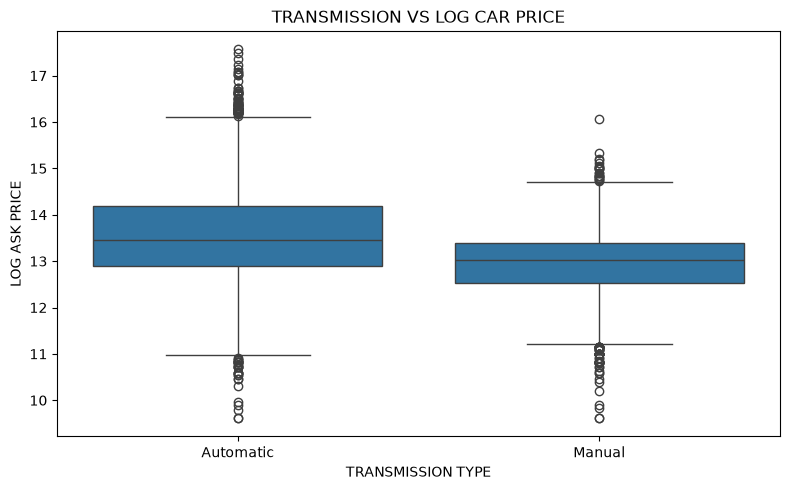

In [180]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Transmission',
    y='AskPrice_log'
)

plt.title('TRANSMISSION VS LOG CAR PRICE')
plt.xlabel('TRANSMISSION TYPE')
plt.ylabel('LOG ASK PRICE')

plt.tight_layout()
plt.show()


AUTOMATIC CARS HAVE A HIGHER MEDIAN LOG ASK PRICE AND GREATER PRICE VARIATION THAN MANUAL CARS. BOTH TRANSMISSION TYPES CONTAIN HIGH- AND LOW-PRICE OUTLIERS. OVERALL, AUTOMATIC CARS TEND TO BE MORE EXPENSIVE IN THIS DATASET.

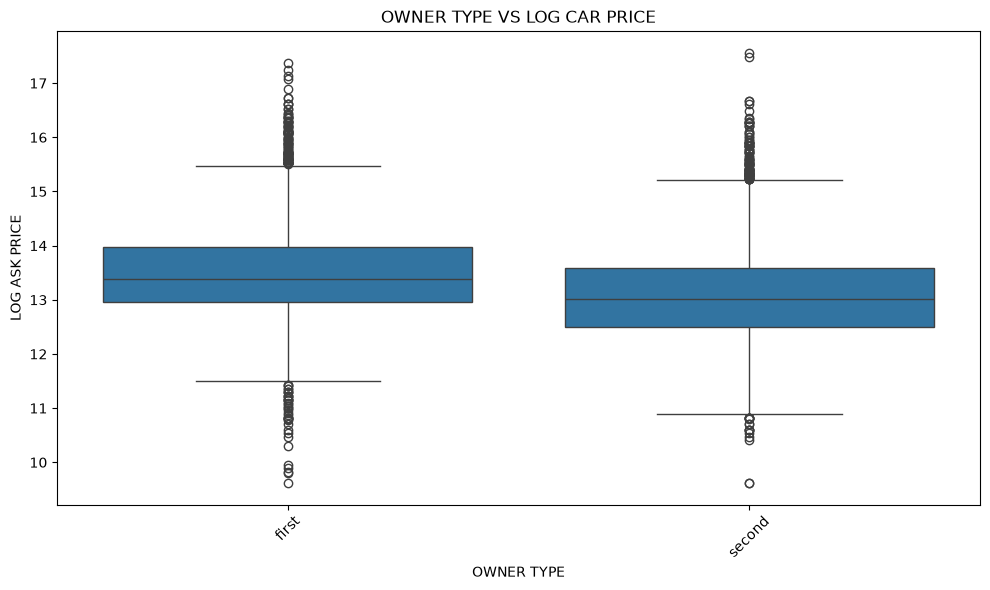

In [181]:

plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='Owner', y='AskPrice_log')

plt.title('OWNER TYPE VS LOG CAR PRICE')
plt.xlabel('OWNER TYPE')
plt.ylabel('LOG ASK PRICE')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


FIRST-OWNER CARS HAVE A HIGHER MEDIAN LOG ASK PRICE (13.38) THAN SECOND-OWNER CARS (13.02). THIS SUGGESTS THAT CARS WITH FEWER PREVIOUS OWNERS TEND TO HAVE HIGHER ASKING PRICES.

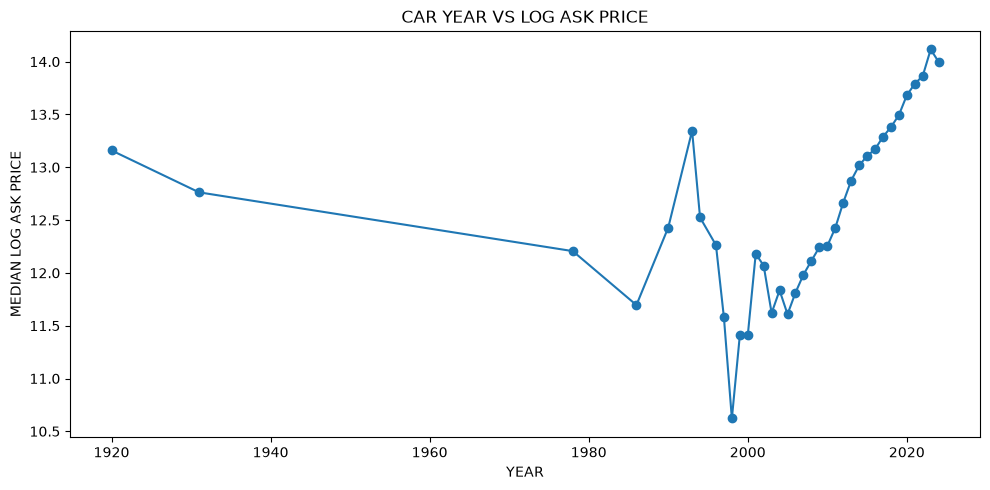

In [182]:

df.groupby('Year')['AskPrice_log'].median().sort_index().plot(
    kind='line',
    figsize=(10, 5),
    marker='o'
)

plt.title('CAR YEAR VS LOG ASK PRICE')
plt.xlabel('YEAR')
plt.ylabel('MEDIAN LOG ASK PRICE')
plt.tight_layout()
plt.show()


YEAR HAS A MODERATE POSITIVE CORRELATION WITH LOG ASK PRICE (0.538). THIS SUGGESTS THAT NEWER CARS GENERALLY HAVE HIGHER ASKING PRICES.

In [183]:

df[['kmDriven', 'AskPrice_log']].corr()

,kmDriven,AskPrice_log
kmDriven,1.000000,-0.148375
AskPrice_log,-0.148375,1.000000


KMDRIVEN HAS A WEAK NEGATIVE CORRELATION WITH LOG ASK PRICE (-0.148). THIS SUGGESTS THAT CARS WITH HIGHER MILEAGE TEND TO HAVE SLIGHTLY LOWER ASKING PRICES.

In [184]:
df[['Age', 'AskPrice_log']].corr()

,Age,AskPrice_log
Age,1.000000,-0.551433
AskPrice_log,-0.551433,1.000000


AGE HAS A MODERATE NEGATIVE CORRELATION WITH LOG ASK PRICE (-0.551). THIS SUGGESTS THAT OLDER CARS GENERALLY HAVE LOWER ASKING PRICES.

In [185]:

df.groupby('Brand')['AskPrice_log'].median().sort_values(ascending=False)

Brand
Rolls-Royce      17.565015
Lamborghini      17.479072
Aston Martin     17.088875
Bentley          16.733281
Hummer           16.097893
Porsche          15.894952
Maserati         15.894952
Toyota Land      15.763458
Lexus            15.398565
Land Rover       15.157048
Mini             14.867197
Mercedes-Benz    14.626441
Jaguar           14.614067
BMW              14.552675
Citroen          14.482024
Volvo            14.375127
Isuzu            14.316286
MG               14.187420
Kia              14.077876
Audi             14.058458
Jeep             14.038655
Force            13.870947
Mitsubishi       13.681980
Mahindra         13.592368
Skoda            13.487008
Toyota           13.473022
Volkswagen       13.208543
Tata             13.203935
Ford             13.178746
Ssangyong        13.102163
Honda            13.071072
Hyundai          13.049795
Maruti Suzuki    12.959847
Ambassador       12.950390
Nissan           12.890427
Renault          12.834684
Fiat             12.42

ROLLS-ROYCE, LAMBORGHINI, AND ASTON MARTIN HAVE THE HIGHEST MEDIAN LOG ASK PRICES. BRANDS SUCH AS OPEL, BAJAJ, AND CHEVROLET HAVE LOWER MEDIAN PRICES. THIS SUGGESTS THAT CAR BRAND IS ASSOCIATED WITH ASKING PRICE.

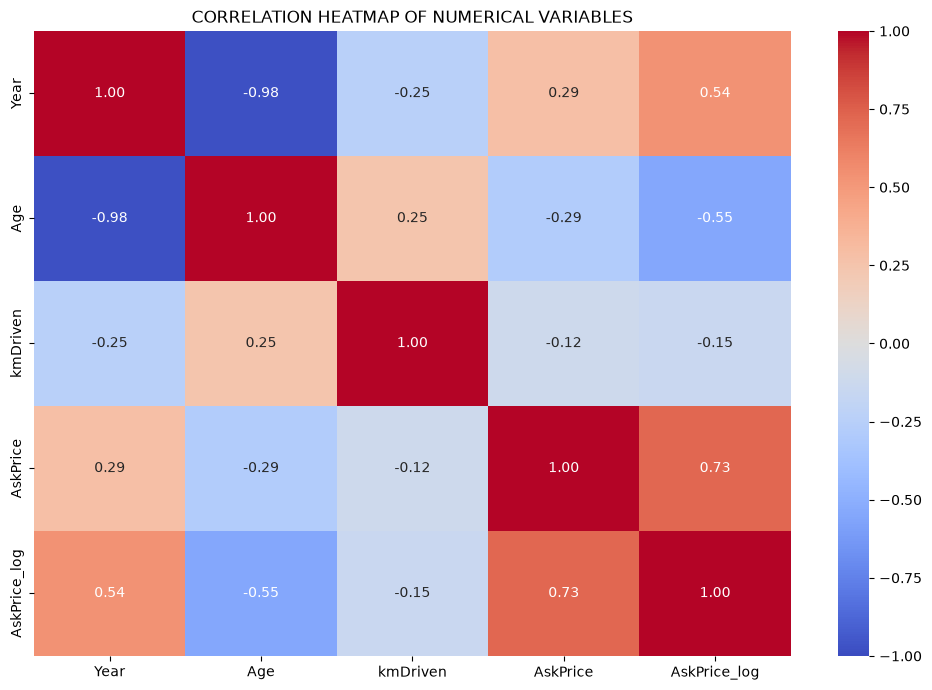

In [186]:
numeric_cols = ['Year', 'Age', 'kmDriven', 'AskPrice', 'AskPrice_log']

correlation = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('CORRELATION HEATMAP OF NUMERICAL VARIABLES')
plt.tight_layout()
plt.show()


THE HEATMAP SHOWS THAT YEAR HAS A MODERATE POSITIVE CORRELATION WITH LOG ASK PRICE (0.54), WHILE AGE HAS A MODERATE NEGATIVE CORRELATION (-0.55). ASKPRICE AND ASKPRICE_LOG ARE STRONGLY POSITIVELY CORRELATED (0.73). YEAR AND AGE ARE VERY STRONGLY NEGATIVELY CORRELATED (-0.98), AS EXPECTED, BECAUSE OLDER CARS HAVE EARLIER MODEL YEARS.

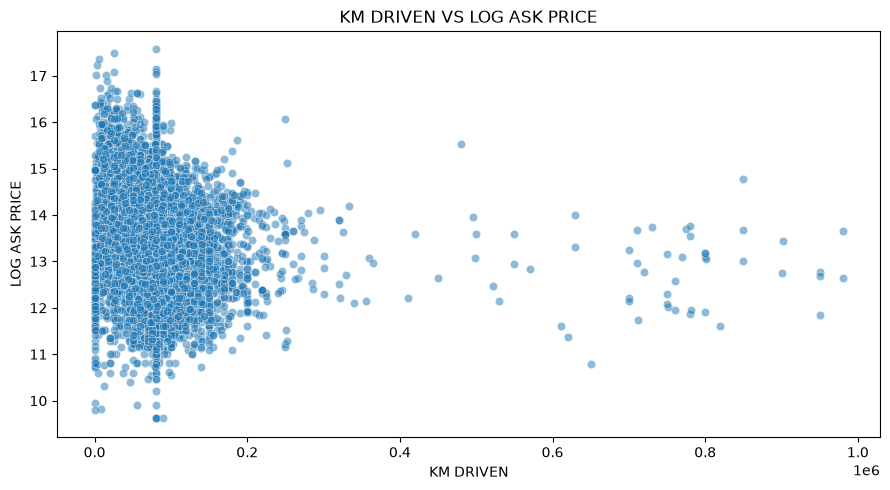

In [187]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='kmDriven',
    y='AskPrice_log',
    alpha=0.5
)

plt.title('KM DRIVEN VS LOG ASK PRICE')
plt.xlabel('KM DRIVEN')
plt.ylabel('LOG ASK PRICE')
plt.tight_layout()
plt.show()


KM DRIVEN VS LOG ASK PRICE: KMDRIVEN HAS A WEAK NEGATIVE CORRELATION WITH LOG ASK PRICE (-0.15), SUGGESTING THAT CARS WITH HIGHER MILEAGE TEND TO HAVE SLIGHTLY LOWER ASKING PRICES.

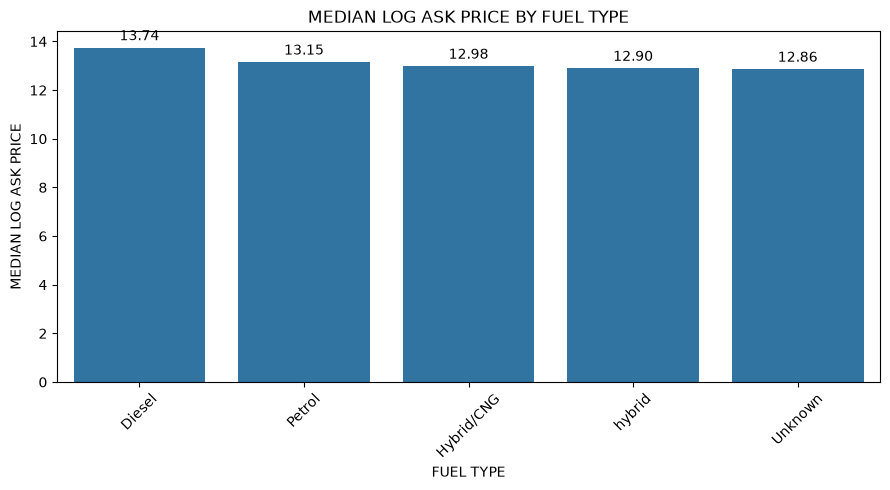

In [188]:

fuel_prices = (
    df.groupby('FuelType')['AskPrice_log']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=fuel_prices.index,
    y=fuel_prices.values
)

plt.title('MEDIAN LOG ASK PRICE BY FUEL TYPE')
plt.xlabel('FUEL TYPE')
plt.ylabel('MEDIAN LOG ASK PRICE')
plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()


FUEL TYPE VS LOG ASK PRICE: DIESEL CARS HAVE THE HIGHEST MEDIAN LOG ASK PRICE (13.74), FOLLOWED BY PETROL (13.15). THIS SUGGESTS THAT FUEL TYPE IS ASSOCIATED WITH CAR PRICES.

In [189]:
df['KmPerYear'] = df['kmDriven'] / df['Age'].replace(0, 1)

KM DRIVEN PER YEAR
This measures how much a car has been driven annually, giving us a better indication of usage than total mileage alone.

In [190]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[-1, 3, 7, 12, float('inf')],
    labels=['NEW', 'RECENT', 'OLDER', 'VERY OLD']
)

VEHICLE AGE GROUP
This groups cars into categories, making it easier to compare prices across newer and older vehicles.

In [191]:
print(df[['Age', 'kmDriven', 'KmPerYear', 'AgeGroup']].head())

    Age       kmDriven     KmPerYear  AgeGroup
0  23.0   98000.000000   4260.869565  VERY OLD
1  15.0  190000.000000  12666.666667  VERY OLD
2  14.0   80089.393405   5720.670957  VERY OLD
3   7.0   80089.393405  11441.341915    RECENT
4   5.0   80089.393405  16017.878681    RECENT


THIS IS THE SECTION OF CODE WHERE I WILL SELECT MY FEATURES AND TRAIN MY MODEL

THE LOG-TRANSFORMED ASKING PRICE THAT THE MODEL WILL LEARN TO PREDICT.

- Brand — IDENTIFIES THE VEHICLE MANUFACTURER.
- model — IDENTIFIES THE SPECIFIC VEHICLE MODEL.
- Year — REPRESENTS THE VEHICLE'S MANUFACTURING YEAR.
- kmDriven — INDICATES THE TOTAL DISTANCE THE VEHICLE HAS TRAVELLED.
- Transmission — IDENTIFIES WHETHER THE VEHICLE IS AUTOMATIC OR MANUAL.
- Owner — INDICATES THE VEHICLE'S OWNERSHIP HISTORY.
- FuelType — IDENTIFIES THE VEHICLE'S FUEL TYPE.
- KmPerYear — ESTIMATES THE AVERAGE DISTANCE TRAVELLED PER YEAR.
- TARGET VARIABLE: AskPrice_log — THE LOG-TRANSFORMED ASKING PRICE THAT THE MODEL WILL LEARN TO PREDICT.

In [193]:
X = df[
    [
        'Brand',
        'model',
        'Year',
        'kmDriven',
        'Transmission',
        'Owner',
        'FuelType',
        'KmPerYear'
    ]
].copy()

y = df['AskPrice_log']

I HAVE SELECTED THESE FOLLOWING MODEL FEATURES AS A COPY ON MY 'X' VARIABLE AND MY TARGET VARIABLE TO 'Y' 

In [ ]:
categorical_features = [
    'Brand',
    'model',
    'Transmission',
    'Owner',
    'FuelType'
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print(X_encoded.head())
print("SHAPE:", X_encoded.shape)

     Year       kmDriven     KmPerYear  Brand_Aston Martin  Brand_Audi  \
0  2001.0   98000.000000   4260.869565                   0           0   
1  2009.0  190000.000000  12666.666667                   0           0   
2  2010.0   80089.393405   5720.670957                   0           0   
3  2017.0   80089.393405  11441.341915                   0           0   
4  2019.0   80089.393405  16017.878681                   0           0   

   Brand_BMW  Brand_Bajaj  Brand_Bentley  Brand_Chevrolet  Brand_Citroen  ...  \
0          0            0              0                0              0  ...   
1          0            0              0                0              0  ...   
2          0            0              0                0              0  ...   
3          0            0              0                0              0  ...   
4          0            0              0                0              0  ...   

   model_i20 N Line  model_maruti-suzuki-brezza  model_maruti-suzuki

I HAVE SELECTED MY CATEGORICAL FEATURES, AND ENCODED THEM, I ALSO REDUCED MULTICOLINIALITY BY DROPPING THE 'AGE' COLUMN AS IT IS HIGHLY CORRELATED TO THE 'YEAR' COLUMN

- BRAND, MODEL, TRANSMISSION, OWNER, FUELTYPE, AND AGEGROUP ARE CATEGORICAL FEATURES THAT NEED ENCODING.

- YEAR AND AGE ARE HIGHLY CORRELATED, SO WE COULD DROP ONE TO REDUCE REDUNDANCY.

- KMPERYEAR IS DERIVED FROM KMDRIVEN AND AGE, SO IT MAY ADD USEFUL USAGE INFORMATION BUT ALSO INTRODUCES REDUNDANCY.

In [195]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

I AM SPLITING THE DATA INTO 80% TRAINING DATA AND 20% TESTING DATA

In [196]:
numeric_features = ['Year', 'kmDriven', 'KmPerYear']

scaler = StandardScaler()

X_train.loc[:, numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test.loc[:, numeric_features] = scaler.transform(
    X_test[numeric_features]
)

print("TRAINING SET:", X_train.shape)
print("TESTING SET:", X_test.shape)


TRAINING SET: (11793, 471)
TESTING SET: (2949, 471)


I AM USING THE StandardScaler TO SCALE Year, kmDriven, AND KmPerYear TO COMPARABLE SCALES
I THEN FIT THE SCALER ON TRAINING DATA ONLY TO PREVENT DATA LEAKAGE, THEN APPLY IT TO THE TEST DATA USING THE SAME SCALING VALUES.

In [197]:

from sklearn.linear_model import LinearRegression


model = LinearRegression()
model.fit(X_train, y_train)

print("MODEL TRAINED SUCCESSFULLY!")

MODEL TRAINED SUCCESSFULLY!


In [198]:

y_pred = model.predict(X_test)
print("SAMPLE PREDICTIONS:", y_pred[:5])

SAMPLE PREDICTIONS: [13.18359019 13.49143032 13.11747904 13.03090077 12.44450249]


I AM TRAINING A LINEAR REGRESSION MODEL USING THE TRAINING DATA TO LEARN PATTERNS BETWEEN THE SELECTED FEATURES AND LOG-TRANSFORMED CAR ASKING PRICES. I THEN USE THE TRAINED MODEL TO PREDICT ASKING PRICES FOR THE TEST DATA TO EVALUATE HOW WELL IT GENERALISES TO UNSEEN DATA

In [199]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² SCORE:", r2)

MAE: 0.24036585128374546
RMSE: 0.4111439592192556
R² SCORE: 0.8005120886969468


I USE MAE, RMSE, AND R² TO MEASURE THE MODEL'S PREDICTION ERRORS AND HOW WELL IT EXPLAINS VARIATIONS IN LOG ASKING PRICES.

AFTER ANALYSISNG THE RESULTS OF MY BASELINE MODEL, I AM OVERALL HAPPY BUT I WANT TO TRY ANOTHER ALGORITHM TO SEE IF THE SCORE CAN IMPROVE. I WILL TRAIN A RandomForestRegressor AND COMPARE ITS PERFORMANCE AGAINST LINEAR REGRESSION.

In [206]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor()

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

I'M USING A RANDOM FOREST BECAUSE IT CAN CAPTURE NON-LINEAR RELATIONSHIPS BETWEEN CAR FEATURES AND ASKING PRICES

In [207]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST MAE:", rf_mae)
print("RANDOM FOREST RMSE:", rf_rmse)
print("RANDOM FOREST R²:", rf_r2)

RANDOM FOREST MAE: 0.24412892888023213
RANDOM FOREST RMSE: 0.37895801931010753
RANDOM FOREST R²: 0.830522925223472


FROM THE RESULT IT IS CLEAR THAT RANDOM FOREST IS BETTER OVERALL AS IT BEATS LINEAR REGRESSION ON RMSE AND R2

MAE: LINEAR REGRESSION IS SLIGHTLY BETTER (0.2404 VS 0.2441).
RMSE: RANDOM FOREST IS BETTER (0.3790 VS 0.4111).
R²: RANDOM FOREST EXPLAINS 83.05% OF THE VARIATION, COMPARED WITH 80.05% FOR LINEAR REGRESSION.

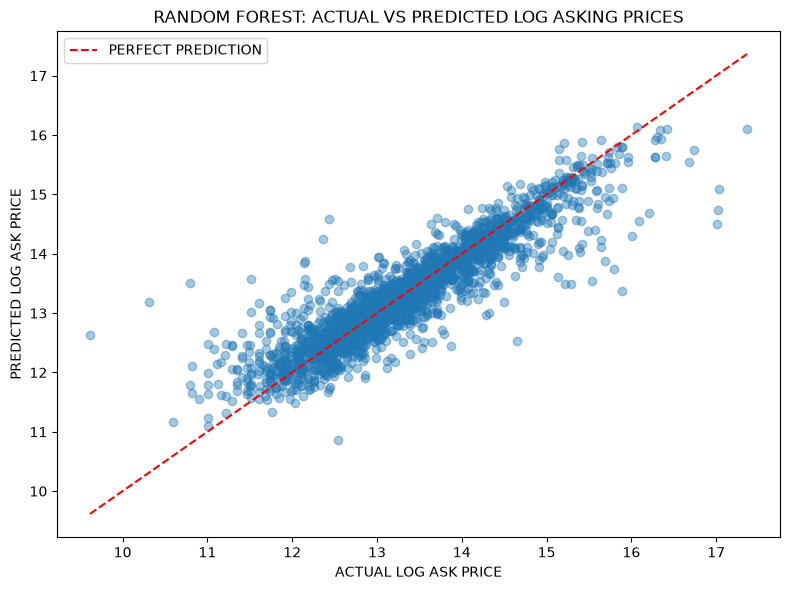

In [203]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='PERFECT PREDICTION'
)

plt.title('RANDOM FOREST: ACTUAL VS PREDICTED LOG ASKING PRICES')
plt.xlabel('ACTUAL LOG ASK PRICE')
plt.ylabel('PREDICTED LOG ASK PRICE')
plt.legend()
plt.tight_layout()
plt.show()


EACH POINT REPRESENTS A CAR. THE CLOSER THE POINT IS TO THE RED DASHED LINE, THE CLOSER THE PREDICTION IS TO THE ACTUAL PRICE

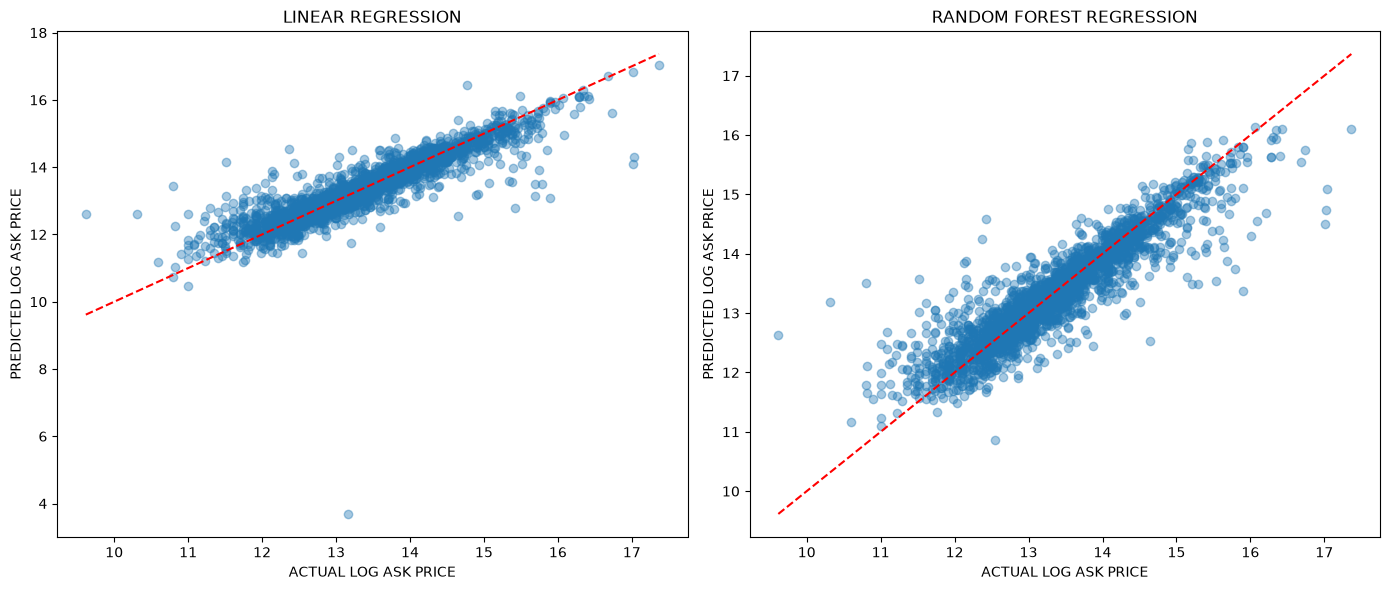

In [202]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))


axes[0].scatter(y_test, y_pred, alpha=0.4)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[0].set_title('LINEAR REGRESSION')
axes[0].set_xlabel('ACTUAL LOG ASK PRICE')
axes[0].set_ylabel('PREDICTED LOG ASK PRICE')


axes[1].scatter(y_test, rf_pred, alpha=0.4)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[1].set_title('RANDOM FOREST REGRESSION')
axes[1].set_xlabel('ACTUAL LOG ASK PRICE')
axes[1].set_ylabel('PREDICTED LOG ASK PRICE')

plt.tight_layout()
plt.show()


THIS IS THE VISUALISATION OF THE PERFORMANCE BETWEEN RANDOM FOREST AND LOGISTIC REGRESSION 

BOTH MODELS FOLLOW THE GENERAL TREND, BUT RANDOM FOREST HAS A BETTER R² SCORE (83.05% VS 80.05%). LINEAR REGRESSION SHOWS A STRONGER LINEAR PATTERN, WHILE RANDOM FOREST HAS MORE SCATTER AT SOME PRICE LEVELS. OVERALL, RANDOM FOREST HAS THE LOWER RMSE, BUT LINEAR REGRESSION HAS SLIGHTLY LOWER MAE.

In [204]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [0.5, 0.8, 1.0]
}


search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_grid,
    n_iter=15,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)


best_model = search.best_estimator_
tuned_pred = best_model.predict(X_test)

print("BEST PARAMETERS:", search.best_params_)
print("BEST CV R²:", search.best_score_)
print("TUNED TEST MAE:", mean_absolute_error(y_test, tuned_pred))
print("TUNED TEST RMSE:", np.sqrt(mean_squared_error(y_test, tuned_pred)))
print("TUNED TEST R²:", r2_score(y_test, tuned_pred))


Fitting 3 folds for each of 15 candidates, totalling 45 fits
BEST PARAMETERS: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 20}
BEST CV R²: 0.7651279250712585
TUNED TEST MAE: 0.28041876962450807
TUNED TEST RMSE: 0.4201265053015581
TUNED TEST R²: 0.7917001684132057


I TUNED THE HYPERPARAMETERS IN AN ATTEMPT TO INCREASE ETHE MODEL'S PERFORMANCE

AFTER THE HYPERPARAMETER TUNING:

THE BASELINE MODEL HAS LOWER PREDICTION ERRORS AND EXPLAINS 83.05% OF THE VARIATION IN LOG ASKING PRICES, COMPARED TO 79.17% FOR THE TUNED MODEL.

In [205]:

from sklearn.model_selection import cross_val_score

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': [0.8, 1.0]
}


search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_


tuned_pred = best_model.predict(X_test)


print("BEST PARAMETERS:", search.best_params_)
print("BEST CV R²:", search.best_score_)
print("TUNED TEST MAE:", mean_absolute_error(y_test, tuned_pred))
print("TUNED TEST RMSE:", np.sqrt(mean_squared_error(y_test, tuned_pred)))
print("TUNED TEST R²:", r2_score(y_test, tuned_pred))


baseline_cv = cross_val_score(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    X_train,
    y_train,
    cv=3,
    scoring='r2',
    n_jobs=1
)

print("BASELINE CV R²:", baseline_cv.mean())

Fitting 3 folds for each of 10 candidates, totalling 30 fits
BEST PARAMETERS: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 30}
BEST CV R²: 0.7866559652376451
TUNED TEST MAE: 0.2541800642263431
TUNED TEST RMSE: 0.39018190862145663
TUNED TEST R²: 0.8203351937816259
BASELINE CV R²: 0.7884421369440363


I AM DOING THIS BECAUSE MY FIRST HYPERPARAMETER TUNING ATTEMPT PRODUCED WORSE RESULTS THAN MY BASELINE RANDOM FOREST MODEL. I WANT TO TEST A MORE TARGETED RANGE OF PARAMETERS AND COMPARE CROSS-VALIDATION SCORES TO IDENTIFY WHETHER I CAN IMPROVE THE MODEL'S PREDICTION ACCURACY AND GENERALISATION.

THE SECOND TUNING ATTEMPT IMPROVED PERFORMANCE COMPARED TO THE FIRST TUNED MODEL, BUT THE ORIGINAL BASELINE STILL PERFORMS BEST. THE SIMILAR CROSS-VALIDATION SCORES SUGGEST THAT THE BASELINE IS A REASONABLE CHOICE.

In [208]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15).to_string(index=False))

            Feature  Importance
               Year    0.330467
Brand_Maruti Suzuki    0.075120
Transmission_Manual    0.066092
Brand_Mercedes-Benz    0.046950
          KmPerYear    0.038591
           kmDriven    0.034927
          Brand_BMW    0.034614
     model_Fortuner    0.020138
   Brand_Land Rover    0.015548
    FuelType_Petrol    0.014761
    FuelType_hybrid    0.014364
         Brand_Audi    0.012351
FuelType_Hybrid/CNG    0.010393
      Brand_Hyundai    0.010133
         Brand_Tata    0.009602


I AM CALCULATING FEATURE IMPORTANCE TO IDENTIFY WHICH VARIABLES CONTRIBUTE MOST TO THE RANDOM FOREST MODEL'S PREDICTIONS. I AM THEN RANKING THE FEATURES TO DETERMINE WHICH FACTORS HAVE THE GREATEST INFLUENCE ON PREDICTED USED-CAR ASKING PRICES.

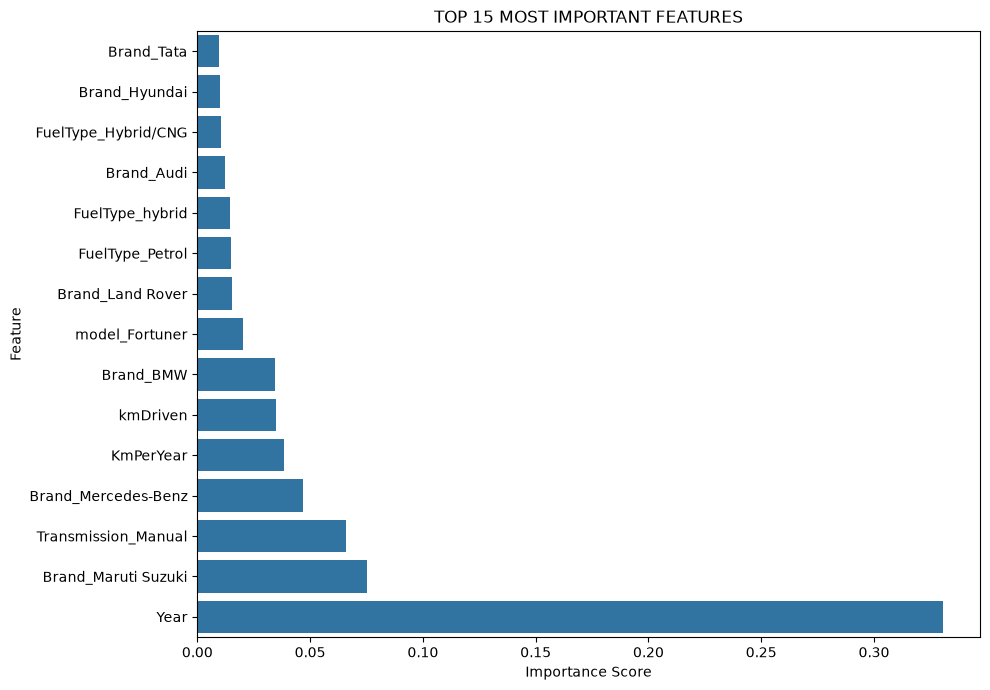

In [209]:
top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('TOP 15 MOST IMPORTANT FEATURES')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

THIS VISUALISATION COMPARES THE 15 MOST IMPORTANT FEATURES AND MAKE IT EASIER TO IDENTIFY WHICH VARIABLES CONTRIBUTE MOST TO THE MODEL'S PREDICTIONS

I FOUND THAT YEAR IS THE MOST IMPORTANT FEATURE, CONTRIBUTING 33.05% TO THE MODEL'S PREDICTIONS. BRAND, TRANSMISSION, AND MILEAGE-RELATED FEATURES ALSO CONTRIBUTE, SUGGESTING THAT VEHICLE AGE, BRAND, TRANSMISSION TYPE, AND USAGE PLAY IMPORTANT ROLES IN PREDICTING ASKING PRICES

In [210]:
train_pred = rf_model.predict(X_train)
test_pred = rf_model.predict(X_test)

print("TRAINING R²:", r2_score(y_train, train_pred))
print("TESTING R²:", r2_score(y_test, test_pred))

TRAINING R²: 0.9700691790771662
TESTING R²: 0.830522925223472


I AM COMPARING TRAINING AND TESTING R² SCORES TO DETERMINE HOW WELL THE MODEL LEARNS THE TRAINING DATA AND GENERALISES TO UNSEEN DATA. A LARGE GAP MAY INDICATE OVERFITTING, WHILE LOW SCORES ON BOTH SETS MAY INDICATE UNDERFITTING

THE TRAINING R² IS 0.9701, WHILE THE TESTING R² IS 0.8305, A GAP OF APPROXIMATELY 0.14. THIS SUGGESTS THAT THE RANDOM FOREST LEARNS THE TRAINING DATA VERY WELL BUT PERFORMS LESS ACCURATELY ON UNSEEN DATA, INDICATING SOME OVERFITTING.

THE PROJECT USED EXPLORATORY DATA ANALYSIS, FEATURE ENGINEERING, AND MACHINE LEARNING TO IDENTIFY FACTORS INFLUENCING USED-CAR ASKING PRICES AND DEVELOP A PREDICTIVE MODEL. THE RANDOM FOREST REGRESSOR PERFORMED BEST OVERALL, ACHIEVING AN R² OF 0.8305, WITH AN MAE OF 0.2441 AND RMSE OF 0.3790 ON LOG-TRANSFORMED ASKING PRICES. YEAR WAS THE MOST IMPORTANT FEATURE, CONTRIBUTING APPROXIMATELY 33% TO THE MODEL'S FEATURE IMPORTANCE. HOWEVER, THE GAP BETWEEN TRAINING R² (0.9701) AND TESTING R² (0.8305) INDICATES SOME OVERFITTING, SO FURTHER IMPROVEMENTS COULD HELP THE MODEL GENERALISE BETTER TO UNSEEN DATA

Key findings
- MODEL PERFORMANCE: THE RANDOM FOREST OUTPERFORMED LINEAR REGRESSION ON R² AND RMSE.
- IMPORTANT FEATURES: YEAR, BRAND, TRANSMISSION, AND MILEAGE-RELATED FEATURES CONTRIBUTED TO PREDICTIONS.
- HYPERPARAMETER TUNING: THE TESTED TUNED MODELS DID NOT OUTPERFORM THE ORIGINAL RANDOM FOREST.
- LIMITATION: THE MODEL SHOWS SIGNS OF OVERFITTING, AND ITS PREDICTIONS ARE BASED ON LOG-TRANSFORMED PRICES.